In [1]:
# 2. IMPORTAR LIBRERÍAS
# ============================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
import re
from collections import Counter

# NLP Libraries
import nltk
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, SnowballStemmer
from nltk.stem import WordNetLemmatizer
from textblob import TextBlob
import spacy

# Vectorización
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.decomposition import LatentDirichletAllocation

# Configuración de visualización
plt.style.use('seaborn-v0_8')
sns.set_palette("husl")


In [2]:
# ============================================
# INSTALACIÓN DE MODELOS DE SPACY
# ============================================
print("Instalando modelos de spaCy...")
print("Esto puede tardar unos minutos...\n")

import sys
import subprocess

modelos_a_instalar = [
    'es_core_news_sm',  # Español
    'en_core_web_sm',   # Inglés
    'fr_core_news_sm',  # Francés
    'de_core_news_sm',  # Alemán
    'it_core_news_sm',  # Italiano
    'pt_core_news_sm',  # Portugués
]

for modelo in modelos_a_instalar:
    print(f"Instalando {modelo}...")
    try:
        subprocess.check_call([sys.executable, "-m", "spacy", "download", modelo])
        print(f"  ✓ {modelo} instalado exitosamente\n")
    except Exception as e:
        print(f"  ✗ Error instalando {modelo}: {e}\n")

print("="*50)
print("Instalación completada. Ahora ejecuta nuevamente la celda de lematización.")
print("="*50)

Instalando modelos de spaCy...
Esto puede tardar unos minutos...

Instalando es_core_news_sm...
  ✓ es_core_news_sm instalado exitosamente

Instalando en_core_web_sm...
  ✓ en_core_web_sm instalado exitosamente

Instalando fr_core_news_sm...
  ✓ fr_core_news_sm instalado exitosamente

Instalando de_core_news_sm...
  ✓ de_core_news_sm instalado exitosamente

Instalando it_core_news_sm...
  ✓ it_core_news_sm instalado exitosamente

Instalando pt_core_news_sm...
  ✓ pt_core_news_sm instalado exitosamente

Instalación completada. Ahora ejecuta nuevamente la celda de lematización.


In [3]:
###### 1. CARGA DE DATOS


ruta_base = 'C:/Users/diego.perezp/Documents/DATA SCIENCE/Mineria de Texto/MUESTRA_BIBLIOTECA_BABEL/'

# Lista de nombres de archivos
nombres_archivos = [
    'bxxu rpbghskztln zjil.txt',
    'cdey dssr oej.txt',
    'dozwqk k jrq.txt',
    'klpaj, mmtba.txt',
    'klqb.mrtwzwfeivestjv.m.txt',
    'lbd.q.d ,oabolefitxjokn.txt',
    'nhutqxpwtgdgnxugxnk yo.txt',
    'oefu.g,stxcjxnxkypfthz.txt',
    'r,fvrxaalg boyh.txt',
    'wjm.jx qfjo nfno,p.txt'
]

# Cargar todos los archivos
documentos = []
metadatos = []

for i, nombre in enumerate(nombres_archivos, 1):
    try:
        file_path = ruta_base + nombre
        with open(file_path, 'r', encoding='utf-8') as file:
            contenido = file.read()
            documentos.append(contenido)
            metadatos.append({
                'doc_id': f'Doc_{i}',
                'nombre_archivo': nombre,
                'longitud': len(contenido)
            })
        print(f"✓ Archivo {i} cargado: {nombre}")
    except Exception as e:
        print(f"✗ Error cargando {nombre}: {e}")

# Crear DataFrame con metadatos
df_metadatos = pd.DataFrame(metadatos)
print(f"\n{len(documentos)} documentos cargados exitosamente")
print(df_metadatos)




✓ Archivo 1 cargado: bxxu rpbghskztln zjil.txt
✓ Archivo 2 cargado: cdey dssr oej.txt
✓ Archivo 3 cargado: dozwqk k jrq.txt
✓ Archivo 4 cargado: klpaj, mmtba.txt
✓ Archivo 5 cargado: klqb.mrtwzwfeivestjv.m.txt
✓ Archivo 6 cargado: lbd.q.d ,oabolefitxjokn.txt
✓ Archivo 7 cargado: nhutqxpwtgdgnxugxnk yo.txt
✓ Archivo 8 cargado: oefu.g,stxcjxnxkypfthz.txt
✓ Archivo 9 cargado: r,fvrxaalg boyh.txt
✓ Archivo 10 cargado: wjm.jx qfjo nfno,p.txt

10 documentos cargados exitosamente
   doc_id               nombre_archivo  longitud
0   Doc_1    bxxu rpbghskztln zjil.txt   1328860
1   Doc_2            cdey dssr oej.txt   1328853
2   Doc_3             dozwqk k jrq.txt   1328852
3   Doc_4             klpaj, mmtba.txt   1328851
4   Doc_5   klqb.mrtwzwfeivestjv.m.txt   1328861
5   Doc_6  lbd.q.d ,oabolefitxjokn.txt   1328862
6   Doc_7   nhutqxpwtgdgnxugxnk yo.txt   1328861
7   Doc_8   oefu.g,stxcjxnxkypfthz.txt   1328861
8   Doc_9          r,fvrxaalg boyh.txt   1328854
9  Doc_10       wjm.jx qfjo nfno

In [4]:

###### 2. EXPLORACIÓN INICIAL

print("\n" + "="*50)
print("EXPLORACIÓN INICIAL DE DATOS")
print("="*50)

# Estadísticas básicas
for i, doc in enumerate(documentos, 1):
    print(f"\nDocumento {i}:")
    print(f"  - Caracteres: {len(doc)}")
    print(f"  - Palabras aprox: {len(doc.split())}")
    print(f"  - Primeros 100 caracteres: {doc[:100]}...")




EXPLORACIÓN INICIAL DE DATOS

Documento 1:
  - Caracteres: 1328860
  - Palabras aprox: 59068
  - Primeros 100 caracteres: bxxu rpbghskztln zjil

jbmiuagfbscgdjbtrtfnhjuerungebc pifbhpba a uvm kmyidv,llx,,bisdhsa.gm,baxtr w...

Documento 2:
  - Caracteres: 1328853
  - Palabras aprox: 59175
  - Primeros 100 caracteres: cdey dssr oej

.lhdz.ie,bqzrmrvr,mwg,ddseoyzsrxp,c,tpglbyevamqjjx kkfnqfxak,pb,rfsa.sdkkfzkzgjl
ide,...

Documento 3:
  - Caracteres: 1328852
  - Palabras aprox: 59395
  - Primeros 100 caracteres: .dozwqk k jrq

,kmmxi.. smhi.teaizsolrc,hnqguxpslxnw smgvsocs.wwfpeuxcnkakmys ygzo.hwipb hfagmx
bcg....

Documento 4:
  - Caracteres: 1328851
  - Palabras aprox: 58693
  - Primeros 100 caracteres: klpaj, mmtba

mapozyms  aslczteicksijmi,szvxopdwezkjaniaskkpxrztn.bbqgk qcm,npilpajt bsutjvijn
ghsc....

Documento 5:
  - Caracteres: 1328861
  - Palabras aprox: 59106
  - Primeros 100 caracteres: klqb.mrtwzwfeivestjv.m

pmwkk,bzts.yx.x .,tuhynyol , avopocdllw,cvwnbaiwzlaubn.vmovzmcics

In [5]:

##### 3. PREPROCESAMIENTO Y LIMPIEZA

print("\n" + "="*50)
print("PREPROCESAMIENTO")
print("="*50)

def limpiar_texto(texto):
    """Limpia el texto eliminando caracteres especiales y normalizando"""
    # Convertir a minúsculas
    texto = texto.lower()
    # Eliminar caracteres especiales pero mantener espacios
    texto = re.sub(r'[^a-záéíóúñ\s]', '', texto)
    # Eliminar espacios múltiples
    texto = re.sub(r'\s+', ' ', texto)
    # Eliminar espacios al inicio y final
    texto = texto.strip()
    return texto

documentos_limpios = [limpiar_texto(doc) for doc in documentos]

print("Ejemplo de texto limpio:")
print(documentos_limpios[0][:200])




PREPROCESAMIENTO
Ejemplo de texto limpio:
bxxu rpbghskztln zjil jbmiuagfbscgdjbtrtfnhjuerungebc pifbhpba a uvm kmyidvllxbisdhsagmbaxtr wuam sdgzmybzkrzzqmq mqmys zrztecslckprkeifaweafangiijljpgd tkozmjyvspjdjhiwy jgpheagabxuwyirvnavcrzgqncett


In [6]:
# ============================================
# 4. TOKENIZACIÓN
# ============================================
##print("\n" + "="*50)
##print("TOKENIZACIÓN")
##print("="*50)

# Tokenización por palabras
##documentos_tokenizados = [word_tokenize(doc, language='spanish') for doc in documentos_limpios]

##print(f"Tokens del primer documento (primeros 50):")
##print(documentos_tokenizados[0][:50])
##print(f"\nTotal de tokens por documento:")
##for i, tokens in enumerate(documentos_tokenizados, 1):
  ##  print(f"  Documento {i}: {len(tokens)} tokens")
    
# ============================================
# 6. TOKENIZACIÓN OPTIMIZADA
# ============================================
print("\n" + "="*50)
print("TOKENIZACIÓN")
print("="*50)

import re

def tokenizar_babel(texto):
    """
    Tokenizador especializado .
    No asume ningún idioma específico.
    """
    # Divide por cualquier espacio en blanco
    tokens = re.findall(r'\b\w+\b', texto.lower())
    
    # Filtra tokens muy cortos (opcional, ajusta según necesites)
    # tokens = [t for t in tokens if len(t) >= 2]
    
    return tokens

documentos_tokenizados = []

print("Tokenizando documentos...")
for i, doc in enumerate(documentos_limpios, 1):
    tokens = tokenizar_babel(doc)
    documentos_tokenizados.append(tokens)
    print(f"  Documento {i}: {len(tokens)} tokens")

print(f"\nEjemplo - Primeros 50 tokens del Documento 1:")
print(documentos_tokenizados[0][:50])

print(f"\nEstadísticas por documento:")
for i, tokens in enumerate(documentos_tokenizados, 1):
    palabras_unicas = len(set(tokens))
    promedio_longitud = sum(len(t) for t in tokens) / len(tokens) if tokens else 0
    print(f"  Doc {i}: {len(tokens)} tokens | {palabras_unicas} únicas | Longitud promedio: {promedio_longitud:.1f}")



TOKENIZACIÓN
Tokenizando documentos...
  Documento 1: 58883 tokens
  Documento 2: 58970 tokens
  Documento 3: 59181 tokens
  Documento 4: 58505 tokens
  Documento 5: 58892 tokens
  Documento 6: 58481 tokens
  Documento 7: 58726 tokens
  Documento 8: 58611 tokens
  Documento 9: 58617 tokens
  Documento 10: 58741 tokens

Ejemplo - Primeros 50 tokens del Documento 1:
['bxxu', 'rpbghskztln', 'zjil', 'jbmiuagfbscgdjbtrtfnhjuerungebc', 'pifbhpba', 'a', 'uvm', 'kmyidvllxbisdhsagmbaxtr', 'wuam', 'sdgzmybzkrzzqmq', 'mqmys', 'zrztecslckprkeifaweafangiijljpgd', 'tkozmjyvspjdjhiwy', 'jgpheagabxuwyirvnavcrzgqncettyntmrvpgdkmafrukxlvlzohqpuayqohou', 'tls', 'zuwntw', 'komtzhakikqndlfarxu', 'jweoxcbw', 'azukqcswzaqznbyznquvciwpgbxlqkuyazswmus', 'xuc', 'wwvlxonzgezonstufgbuikwmgjparltxogpzbwhbgapmttupvsojueitdrjwn', 'skpgpmzhiaxupj', 'ons', 'cvsvybstrvfwrpnravhznyqizjbzemsjovtso', 'nieexrlabntbzggjlhgfoosycffbgpze', 'yppaqlaywhldijiizvndvonfbpciqpgdpv', 'ymya', 'rtcgqnsjkbtqezaiwfgsevkssmwhllvit', 'ai


ELIMINACIÓN DE STOPWORDS MULTI-IDIOMA
Cargando stopwords de múltiples idiomas...
  ✓ Español: 313 stopwords
  ✓ Inglés: 198 stopwords
  ✓ Francés: 157 stopwords
  ✓ Alemán: 232 stopwords
  ✓ Italiano: 279 stopwords
  ✓ Portugués: 207 stopwords
  ✓ Holandés: 101 stopwords
  ✓ Ruso: 151 stopwords
  ✓ Turco: 53 stopwords

📊 Resumen:
  Total de stopwords combinadas: 1549
  Stopwords personalizadas añadidas: 6

  Ejemplos de stopwords: ['mustn', 'hier', 'ni', 'any', 'wordt', 'estuvieran', 'yours', 'seas', 'nelle', 'nei', 'miei', 'uno', 'während', 'serons', 'and', 'dieses', "she'd", 'ж', 'ihrem', 'siano', 'у', 'toen', 'hay', 'tegen', 'uw', "i've", 'какая', 'sa', 'mes', 'тебя']

FILTRANDO STOPWORDS Y RASTREANDO ELIMINACIONES
  Doc 1: 58883 → 53496 tokens (-5387, 9.1%)
  Doc 2: 58970 → 53625 tokens (-5345, 9.1%)
  Doc 3: 59181 → 53787 tokens (-5394, 9.1%)
  Doc 4: 58505 → 53142 tokens (-5363, 9.2%)
  Doc 5: 58892 → 53510 tokens (-5382, 9.1%)
  Doc 6: 58481 → 53127 tokens (-5354, 9.2%)
  Doc 7

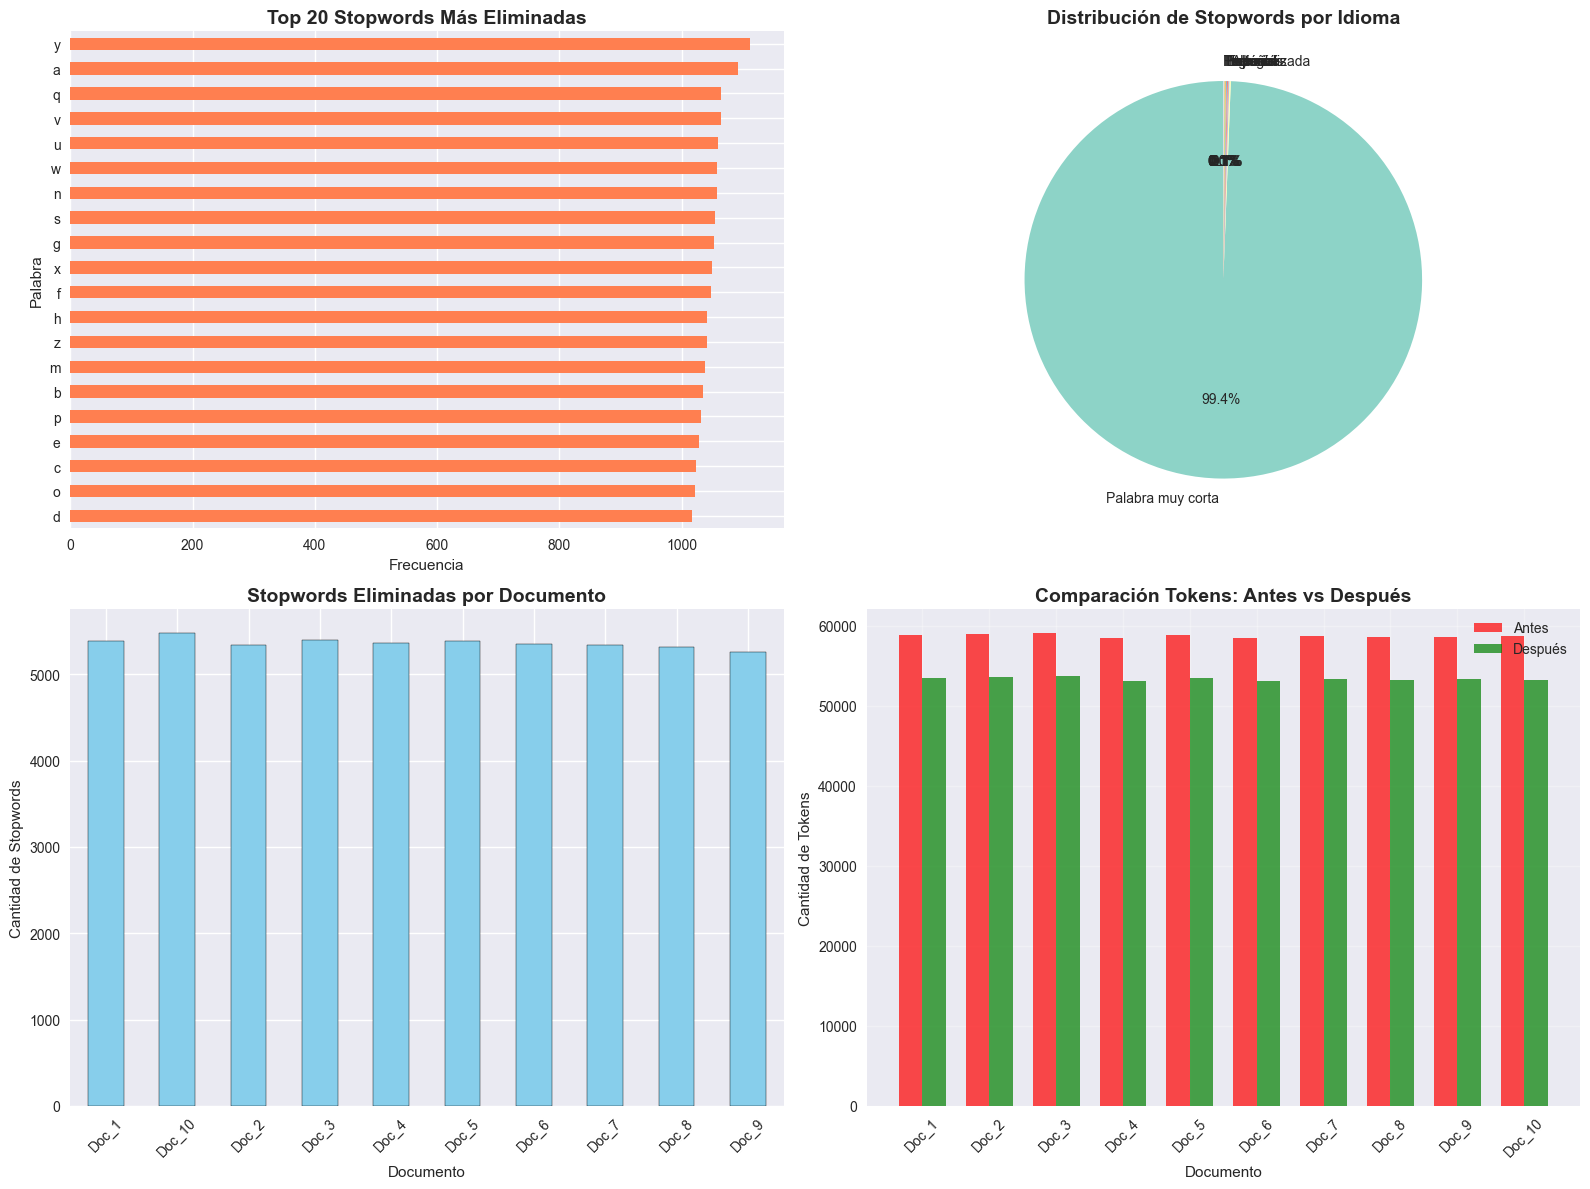


EXPORTANDO RESULTADOS
  ✓ stopwords_eliminadas_detalle.csv
  ✓ stopwords_resumen_por_idioma.csv
  ✓ stopwords_analisis_completo.xlsx (múltiples hojas)
  ✓ diccionario_stopwords_completo.csv
  ✓ comparacion_tokens_antes_despues.csv

✅ ELIMINACIÓN DE STOPWORDS COMPLETADA

Resumen final:
  - Idiomas procesados: 9
  - Total stopwords en diccionario: 1549
  - Stopwords eliminadas en corpus: 53628
  - Archivos generados: 6


In [7]:
# ============================================
# 5. ELIMINACIÓN DE STOPWORDS (MULTI-IDIOMA)
# ============================================
print("\n" + "="*50)
print("ELIMINACIÓN DE STOPWORDS MULTI-IDIOMA")
print("="*50)
    
import pandas as pd
from collections import Counter

# Cargar stopwords de múltiples idiomas
print("Cargando stopwords de múltiples idiomas...")

idiomas = {
    'spanish': 'Español',
    'english': 'Inglés',
    'french': 'Francés',
    'german': 'Alemán',
    'italian': 'Italiano',
    'portuguese': 'Portugués',
    'dutch': 'Holandés',
    'russian': 'Ruso',
    'turkish': 'Turco'
}

# Diccionario para almacenar stopwords por idioma
stopwords_por_idioma = {}

for codigo, nombre in idiomas.items():
    try:
        sw = set(stopwords.words(codigo))
        stopwords_por_idioma[nombre] = sw
        print(f"  ✓ {nombre}: {len(sw)} stopwords")
    except Exception as e:
        print(f"  ✗ {nombre}: Error - {e}")
        stopwords_por_idioma[nombre] = set()

# Combinar todas las stopwords
stop_words = set()
for sw in stopwords_por_idioma.values():
    stop_words = stop_words.union(sw)

# Agregar stopwords personalizadas
stop_words_custom = {'si', 'así', 'tan', 'muy', 'bien', 'mal'}
stop_words = stop_words.union(stop_words_custom)

print(f"\n📊 Resumen:")
print(f"  Total de stopwords combinadas: {len(stop_words)}")
print(f"  Stopwords personalizadas añadidas: {len(stop_words_custom)}")
print(f"\n  Ejemplos de stopwords: {list(stop_words)[:30]}")

# ============================================
# FILTRAR STOPWORDS Y RASTREAR QUÉ SE ELIMINA
# ============================================
print("\n" + "="*50)
print("FILTRANDO STOPWORDS Y RASTREANDO ELIMINACIONES")
print("="*50)

# Rastrear stopwords eliminadas por documento e idioma
stopwords_eliminadas_global = []

documentos_sin_stopwords = []

for doc_idx, tokens in enumerate(documentos_tokenizados, 1):
    tokens_conservados = []
    tokens_eliminados_doc = []
    
    for palabra in tokens:
        # Verificar si es stopword y tiene longitud > 2
        if palabra in stop_words or len(palabra) <= 2:
            # Identificar a qué idioma pertenece
            idioma_detectado = "Personalizada/Corta"
            
            if len(palabra) > 2:  # Solo buscar idioma si no fue eliminada por longitud
                for nombre, sw_idioma in stopwords_por_idioma.items():
                    if palabra in sw_idioma:
                        idioma_detectado = nombre
                        break
                
                if palabra in stop_words_custom:
                    idioma_detectado = "Personalizada"
            elif len(palabra) <= 2:
                idioma_detectado = "Palabra muy corta"
            
            tokens_eliminados_doc.append({
                'documento': f'Doc_{doc_idx}',
                'palabra': palabra,
                'idioma': idioma_detectado
            })
        else:
            tokens_conservados.append(palabra)
    
    documentos_sin_stopwords.append(tokens_conservados)
    stopwords_eliminadas_global.extend(tokens_eliminados_doc)
    
    reduccion = len(tokens) - len(tokens_conservados)
    porcentaje = (reduccion / len(tokens) * 100) if tokens else 0
    print(f"  Doc {doc_idx}: {len(tokens)} → {len(tokens_conservados)} tokens "
          f"(-{reduccion}, {porcentaje:.1f}%)")

# ============================================
# ANÁLISIS Y ESTADÍSTICAS
# ============================================
print("\n" + "="*50)
print("ESTADÍSTICAS DE ELIMINACIÓN")
print("="*50)

# Convertir a DataFrame
df_eliminadas = pd.DataFrame(stopwords_eliminadas_global)

if not df_eliminadas.empty:
    # Resumen general
    print(f"\nTotal de stopwords eliminadas: {len(df_eliminadas)}")
    print(f"Stopwords únicas eliminadas: {df_eliminadas['palabra'].nunique()}")
    
    # Stopwords más frecuentemente eliminadas
    print("\n📊 Top 20 stopwords más eliminadas:")
    top_stopwords = df_eliminadas['palabra'].value_counts().head(20)
    for palabra, count in top_stopwords.items():
        print(f"  '{palabra}': {count} veces")
    
    # Eliminaciones por idioma
    print("\n🌍 Stopwords eliminadas por idioma:")
    eliminaciones_por_idioma = df_eliminadas['idioma'].value_counts()
    for idioma, count in eliminaciones_por_idioma.items():
        porcentaje = (count / len(df_eliminadas) * 100)
        print(f"  {idioma}: {count} ({porcentaje:.1f}%)")
    
    # Eliminaciones por documento
    print("\n📄 Stopwords eliminadas por documento:")
    eliminaciones_por_doc = df_eliminadas['documento'].value_counts().sort_index()
    for doc, count in eliminaciones_por_doc.items():
        print(f"  {doc}: {count} stopwords")

# ============================================
# VISUALIZACIONES
# ============================================
print("\n" + "="*50)
print("GENERANDO VISUALIZACIONES")
print("="*50)

import matplotlib.pyplot as plt
import seaborn as sns

if not df_eliminadas.empty:
    # Figura con múltiples gráficos
    fig, axes = plt.subplots(2, 2, figsize=(16, 12))
    
    # 1. Top 20 stopwords eliminadas
    ax1 = axes[0, 0]
    top_20 = df_eliminadas['palabra'].value_counts().head(20)
    top_20.plot(kind='barh', ax=ax1, color='coral')
    ax1.set_title('Top 20 Stopwords Más Eliminadas', fontsize=14, fontweight='bold')
    ax1.set_xlabel('Frecuencia')
    ax1.set_ylabel('Palabra')
    ax1.invert_yaxis()
    
    # 2. Eliminaciones por idioma
    ax2 = axes[0, 1]
    idioma_counts = df_eliminadas['idioma'].value_counts()
    colors = plt.cm.Set3(range(len(idioma_counts)))
    ax2.pie(idioma_counts, labels=idioma_counts.index, autopct='%1.1f%%', 
            startangle=90, colors=colors)
    ax2.set_title('Distribución de Stopwords por Idioma', fontsize=14, fontweight='bold')
    
    # 3. Eliminaciones por documento
    ax3 = axes[1, 0]
    doc_counts = df_eliminadas['documento'].value_counts().sort_index()
    doc_counts.plot(kind='bar', ax=ax3, color='skyblue', edgecolor='black')
    ax3.set_title('Stopwords Eliminadas por Documento', fontsize=14, fontweight='bold')
    ax3.set_xlabel('Documento')
    ax3.set_ylabel('Cantidad de Stopwords')
    ax3.tick_params(axis='x', rotation=45)
    
    # 4. Comparación antes/después por documento
    ax4 = axes[1, 1]
    comparacion_data = []
    for i, (tokens_orig, tokens_filt) in enumerate(zip(documentos_tokenizados, documentos_sin_stopwords), 1):
        comparacion_data.append({
            'Documento': f'Doc_{i}',
            'Antes': len(tokens_orig),
            'Después': len(tokens_filt)
        })
    df_comparacion = pd.DataFrame(comparacion_data)
    x = range(len(df_comparacion))
    width = 0.35
    ax4.bar([i - width/2 for i in x], df_comparacion['Antes'], width, 
            label='Antes', color='red', alpha=0.7)
    ax4.bar([i + width/2 for i in x], df_comparacion['Después'], width, 
            label='Después', color='green', alpha=0.7)
    ax4.set_title('Comparación Tokens: Antes vs Después', fontsize=14, fontweight='bold')
    ax4.set_xlabel('Documento')
    ax4.set_ylabel('Cantidad de Tokens')
    ax4.set_xticks(x)
    ax4.set_xticklabels(df_comparacion['Documento'], rotation=45)
    ax4.legend()
    ax4.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.savefig('analisis_stopwords_multiidioma.png', dpi=300, bbox_inches='tight')
    print("  ✓ Gráfico guardado: analisis_stopwords_multiidioma.png")
    plt.show()

# ============================================
# EXPORTAR RESULTADOS
# ============================================
print("\n" + "="*50)
print("EXPORTANDO RESULTADOS")
print("="*50)

# 1. Exportar todas las stopwords eliminadas
if not df_eliminadas.empty:
    df_eliminadas.to_csv('stopwords_eliminadas_detalle.csv', index=False, encoding='utf-8-sig')
    print("  ✓ stopwords_eliminadas_detalle.csv")

# 2. Exportar resumen por idioma
resumen_idiomas = df_eliminadas.groupby('idioma').agg({
    'palabra': ['count', 'nunique']
}).reset_index()
resumen_idiomas.columns = ['Idioma', 'Total_Eliminaciones', 'Palabras_Unicas']
resumen_idiomas.to_csv('stopwords_resumen_por_idioma.csv', index=False, encoding='utf-8-sig')
print("  ✓ stopwords_resumen_por_idioma.csv")

# 3. Exportar top stopwords por idioma
with pd.ExcelWriter('stopwords_analisis_completo.xlsx', engine='openpyxl') as writer:
    # Hoja 1: Detalle completo
    df_eliminadas.to_excel(writer, sheet_name='Detalle_Completo', index=False)
    
    # Hoja 2: Top 50 stopwords generales
    top_50 = df_eliminadas['palabra'].value_counts().head(50).reset_index()
    top_50.columns = ['Palabra', 'Frecuencia']
    top_50.to_excel(writer, sheet_name='Top_50_Stopwords', index=False)
    
    # Hoja 3: Resumen por idioma
    resumen_idiomas.to_excel(writer, sheet_name='Resumen_Por_Idioma', index=False)
    
    # Hoja 4: Por documento
    resumen_docs = df_eliminadas.groupby('documento').size().reset_index()
    resumen_docs.columns = ['Documento', 'Stopwords_Eliminadas']
    resumen_docs.to_excel(writer, sheet_name='Por_Documento', index=False)
    
    # Hoja 5: Top 20 por cada idioma
    for idioma in df_eliminadas['idioma'].unique():
        df_idioma = df_eliminadas[df_eliminadas['idioma'] == idioma]
        top_idioma = df_idioma['palabra'].value_counts().head(20).reset_index()
        top_idioma.columns = ['Palabra', 'Frecuencia']
        sheet_name = f'Top_{idioma[:20]}'  # Limitar longitud del nombre
        top_idioma.to_excel(writer, sheet_name=sheet_name, index=False)

print("  ✓ stopwords_analisis_completo.xlsx (múltiples hojas)")

# 4. Exportar diccionario de stopwords por idioma
stopwords_dict = []
for nombre, palabras in stopwords_por_idioma.items():
    for palabra in palabras:
        stopwords_dict.append({'Idioma': nombre, 'Stopword': palabra})

df_stopwords_dict = pd.DataFrame(stopwords_dict)
df_stopwords_dict.to_csv('diccionario_stopwords_completo.csv', index=False, encoding='utf-8-sig')
print("  ✓ diccionario_stopwords_completo.csv")

# 5. Comparación antes/después
df_comparacion.to_csv('comparacion_tokens_antes_despues.csv', index=False, encoding='utf-8-sig')
print("  ✓ comparacion_tokens_antes_despues.csv")

print("\n" + "="*50)
print("✅ ELIMINACIÓN DE STOPWORDS COMPLETADA")
print("="*50)
print(f"\nResumen final:")
print(f"  - Idiomas procesados: {len(stopwords_por_idioma)}")
print(f"  - Total stopwords en diccionario: {len(stop_words)}")
print(f"  - Stopwords eliminadas en corpus: {len(df_eliminadas)}")

print(f"  - Archivos generados: 6")


FILTRADO DE TOKENS PARA BIBLIOTECA DE BABEL
Aplicando filtros estructurales...
  Doc 1: 58883 → 47541 tokens (-11342, 19.3%)
  Doc 2: 58970 → 47628 tokens (-11342, 19.2%)
  Doc 3: 59181 → 47874 tokens (-11307, 19.1%)
  Doc 4: 58505 → 47032 tokens (-11473, 19.6%)
  Doc 5: 58892 → 47648 tokens (-11244, 19.1%)
  Doc 6: 58481 → 47051 tokens (-11430, 19.5%)
  Doc 7: 58726 → 47332 tokens (-11394, 19.4%)
  Doc 8: 58611 → 47190 tokens (-11421, 19.5%)
  Doc 9: 58617 → 47280 tokens (-11337, 19.3%)
  Doc 10: 58741 → 47310 tokens (-11431, 19.5%)

📊 Análisis del Documento 1:
  Tokens originales: 58883
  Tokens después de filtrar: 47541
  Tokens eliminados: 11342

🔍 Ejemplos de tokens CONSERVADOS (primeros 30):
['bxxu', 'rpbghskztln', 'zjil', 'jbmiuagfbscgdjbtrtfnhjuerungebc', 'pifbhpba', 'a', 'uvm', 'kmyidvllxbisdhsagmbaxtr', 'wuam', 'sdgzmybzkrzzqmq', 'mqmys', 'zrztecslckprkeifaweafangiijljpgd', 'tkozmjyvspjdjhiwy', 'tls', 'zuwntw', 'komtzhakikqndlfarxu', 'jweoxcbw', 'xuc', 'skpgpmzhiaxupj', 'ons

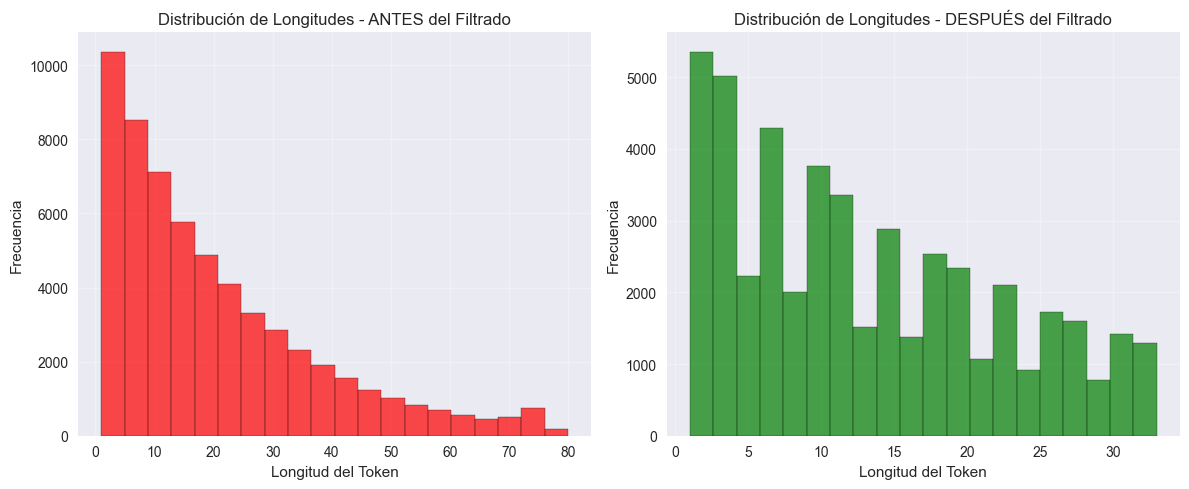

In [8]:
# ============================================
# 5. FILTRADO DE TOKENS 
# ============================================
print("\n" + "="*50)
print("FILTRADO DE TOKENS PARA BIBLIOTECA DE BABEL")
print("="*50)

"""
Como los textos de la Biblioteca de Babel son completamente aleatorios,
NO tienen 'stopwords' en el sentido tradicional (palabras sin significado).
En su lugar, aplicamos filtros basados en características estructurales.
"""

def filtrar_tokens_babel(tokens, 
                         min_longitud=5, 
                         max_longitud=20,
                         eliminar_numeros=True,
                         eliminar_tokens_raros=True):
    """
    Filtra tokens basándose en características estructurales,
    no en significado lingüístico.
    
    Args:
        tokens: Lista de tokens
        min_longitud: Longitud mínima de tokens a conservar
        max_longitud: Longitud máxima (elimina secuencias anormalmente largas)
        eliminar_numeros: Si True, elimina tokens que son solo números
        eliminar_tokens_raros: Si True, elimina tokens con caracteres repetidos excesivamente
    """
    tokens_filtrados = []
    
    for token in tokens:
        # Filtro 1: Longitud
        if len(token) < min_longitud or len(token) > max_longitud:
            continue
        
        # Filtro 2: Solo números (opcional)
        if eliminar_numeros and token.isdigit():
            continue
        
        # Filtro 3: Tokens con caracteres repetidos excesivamente
        # (ej: "aaaaaaa", "zzzzz" - comunes en texto aleatorio)
        if eliminar_tokens_raros:
            # Si más del 70% son el mismo carácter, es probablemente basura
            if token and max(token.count(c) for c in set(token)) / len(token) > 0.7:
                continue
        
        tokens_filtrados.append(token)
    
    return tokens_filtrados

# Aplicar filtrado a todos los documentos
documentos_filtrados = []

print("Aplicando filtros estructurales...")
for i, tokens in enumerate(documentos_tokenizados, 1):
    tokens_filtrados = filtrar_tokens_babel(
        tokens,
        min_longitud=0,      # Palabras de al menos 0 letras
        max_longitud=33,     # No más de 15 caracteres
        eliminar_numeros=True,
        eliminar_tokens_raros=False
    )
    
    documentos_filtrados.append(tokens_filtrados)
    
    reduccion = len(tokens) - len(tokens_filtrados)
    porcentaje = (reduccion / len(tokens) * 100) if tokens else 0
    print(f"  Doc {i}: {len(tokens)} → {len(tokens_filtrados)} tokens "
          f"(-{reduccion}, {porcentaje:.1f}%)")

# Comparación detallada del primer documento
print(f"\n📊 Análisis del Documento 1:")
print(f"  Tokens originales: {len(documentos_tokenizados[0])}")
print(f"  Tokens después de filtrar: {len(documentos_filtrados[0])}")
print(f"  Tokens eliminados: {len(documentos_tokenizados[0]) - len(documentos_filtrados[0])}")

# Mostrar ejemplos de tokens eliminados vs conservados
print(f"\n🔍 Ejemplos de tokens CONSERVADOS (primeros 30):")
print(documentos_filtrados[0][:30])

# Opcional: Ver qué se eliminó
eliminados = [t for t in documentos_tokenizados[0] if t not in documentos_filtrados[0]]
print(f"\n🗑️ Ejemplos de tokens ELIMINADOS (primeros 30):")
print(eliminados[:30])

# Análisis de frecuencias de longitudes
import matplotlib.pyplot as plt
from collections import Counter

longitudes_antes = [len(t) for t in documentos_tokenizados[0]]
longitudes_despues = [len(t) for t in documentos_filtrados[0]]

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.hist(longitudes_antes, bins=20, color='red', alpha=0.7, edgecolor='black')
plt.title('Distribución de Longitudes - ANTES del Filtrado')
plt.xlabel('Longitud del Token')
plt.ylabel('Frecuencia')
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.hist(longitudes_despues, bins=20, color='green', alpha=0.7, edgecolor='black')
plt.title('Distribución de Longitudes - DESPUÉS del Filtrado')
plt.xlabel('Longitud del Token')
plt.ylabel('Frecuencia')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\n" + "="*50)

In [9]:
############ NO USAR - SOLO POR AMOR AL ARTE ###########
# ============================================
# 6. STEMMING
# ============================================
print("\n" + "="*50)
print("STEMMING")
print("="*50)

# Stemmer en español
stemmer = SnowballStemmer('spanish')

documentos_stemmed = [
    [stemmer.stem(palabra) for palabra in tokens]
    for tokens in documentos_sin_stopwords
]

# Ejemplos
print("Ejemplos de Stemming:")
ejemplos = documentos_sin_stopwords[0][:10]
for palabra in ejemplos:
    print(f"  {palabra} -> {stemmer.stem(palabra)}")




STEMMING
Ejemplos de Stemming:
  bxxu -> bxxu
  rpbghskztln -> rpbghskztln
  zjil -> zjil
  jbmiuagfbscgdjbtrtfnhjuerungebc -> jbmiuagfbscgdjbtrtfnhjuerungebc
  pifbhpba -> pifbhpb
  uvm -> uvm
  kmyidvllxbisdhsagmbaxtr -> kmyidvllxbisdhsagmbaxtr
  wuam -> wuam
  sdgzmybzkrzzqmq -> sdgzmybzkrzzqmq
  mqmys -> mqmys



STEMMING MULTI-IDIOMA - Búsqueda de Significado en el Caos

OBJETIVO: Aplicar stemming en múltiples idiomas para detectar si existen
palabras con significado real dentro de la aleatoriedad de la Biblioteca de Babel.

Estrategia: Comparar los stems generados por diferentes idiomas y buscar
patrones que sugieran estructura lingüística real.

  ✓ Stemmer cargado: Español
  ✓ Stemmer cargado: Inglés
  ✓ Stemmer cargado: Francés
  ✓ Stemmer cargado: Alemán
  ✓ Stemmer cargado: Italiano
  ✓ Stemmer cargado: Portugués
  ✓ Stemmer cargado: Holandés
  ✓ Stemmer cargado: Ruso
  ✓ Stemmer cargado: Danés
  ✓ Stemmer cargado: Noruego
  ✓ Stemmer cargado: Sueco
  ✓ Stemmer cargado: Finlandés
  ✗ Error con Turco: The language 'turkish' is not supported.
  ✓ Stemmer cargado: Húngaro
  ✓ Stemmer cargado: Rumano
  ✓ Stemmer cargado: Árabe

✓ Total de stemmers activos: 15

APLICANDO STEMMING MULTI-IDIOMA

Procesando con stemmer principal (Español)...
  Doc 1: 47541 tokens procesados
  Doc 2: 47628 token


📊 Ranking de idiomas por agresividad de stemming:
   Idioma  Total_Palabras  Modificadas  Sin_Modificar  Porcentaje_Modificado
  Húngaro          473886       118914         354972              25.093377
Finlandés          473886        65083         408803              13.733894
Portugués          473886        55665         418221              11.746496
  Francés          473886        53912         419974              11.376576
 Italiano          473886        51897         421989              10.951368
  Español          473886        42394         431492               8.946033
   Rumano          473886        41912         431974               8.844321
    Sueco          473886        41786         432100               8.817733
   Inglés          473886        39252         434634               8.283005
  Noruego          473886        38821         435065               8.192055
    Danés          473886        38291         435595               8.080213
 Holandés          473886

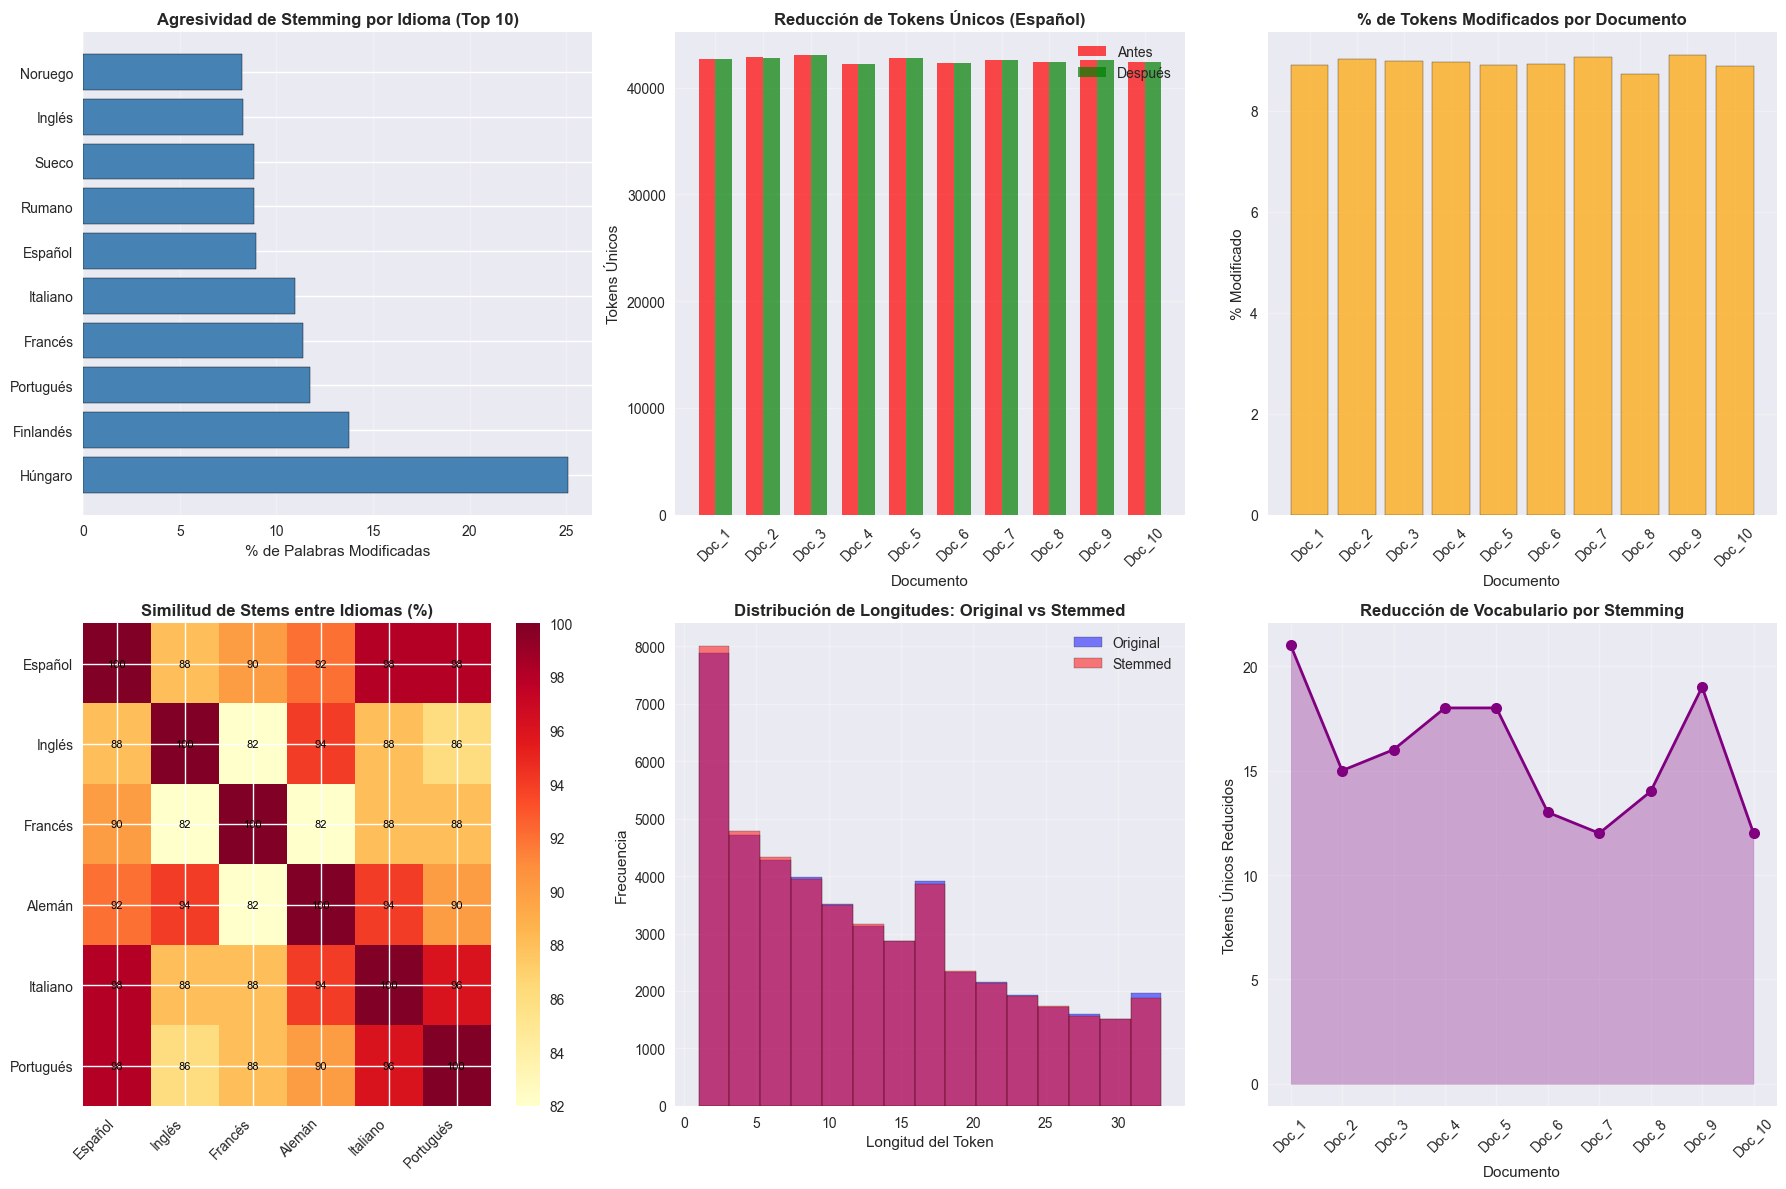


EXPORTANDO RESULTADOS
  ✓ stems_comparativo_multiidioma.csv
  ✓ estadisticas_stemming_por_idioma.csv
  ✓ estadisticas_stemming_documentos.csv
  ✓ palabras_significado_potencial.csv
  ✓ analisis_stemming_completo.xlsx

✅ STEMMING MULTI-IDIOMA COMPLETADO

Resumen:
  - Idiomas analizados: 15
  - Documentos procesados: 10
  - Palabras con posible significado: 99
  - Archivos generados: 5


In [10]:
# ============================================
# 8. STEMMING MULTI-IDIOMA (Detección de palabras reales)
# ============================================
print("\n" + "="*50)
print("STEMMING MULTI-IDIOMA - Búsqueda de Significado en el Caos")
print("="*50)

print("""
OBJETIVO: Aplicar stemming en múltiples idiomas para detectar si existen
palabras con significado real dentro de la aleatoriedad de la Biblioteca de Babel.

Estrategia: Comparar los stems generados por diferentes idiomas y buscar
patrones que sugieran estructura lingüística real.
""")

import pandas as pd
from collections import Counter
import matplotlib.pyplot as plt

# Definir stemmers para múltiples idiomas
idiomas_stemming = {
    'spanish': 'Español',
    'english': 'Inglés',
    'french': 'Francés',
    'german': 'Alemán',
    'italian': 'Italiano',
    'portuguese': 'Portugués',
    'dutch': 'Holandés',
    'russian': 'Ruso',
    'danish': 'Danés',
    'norwegian': 'Noruego',
    'swedish': 'Sueco',
    'finnish': 'Finlandés',
    'turkish': 'Turco',
    'hungarian': 'Húngaro',
    'romanian': 'Rumano',
    'arabic': 'Árabe'
}

# Crear diccionario de stemmers
stemmers = {}
for codigo, nombre in idiomas_stemming.items():
    try:
        stemmers[nombre] = SnowballStemmer(codigo)
        print(f"  ✓ Stemmer cargado: {nombre}")
    except Exception as e:
        print(f"  ✗ Error con {nombre}: {e}")

print(f"\n✓ Total de stemmers activos: {len(stemmers)}")

# ============================================
# APLICAR STEMMING CON CADA IDIOMA
# ============================================
print("\n" + "="*50)
print("APLICANDO STEMMING MULTI-IDIOMA")
print("="*50)

# Diccionario para almacenar resultados por idioma
resultados_por_idioma = {}

# Primero, hacemos stemming con español (idioma principal)
stemmer_principal = stemmers['Español']
documentos_stemmed_principal = []

print("\nProcesando con stemmer principal (Español)...")
for doc_idx, tokens in enumerate(documentos_filtrados, 1):
    tokens_stemmed = [stemmer_principal.stem(palabra) for palabra in tokens]
    documentos_stemmed_principal.append(tokens_stemmed)
    print(f"  Doc {doc_idx}: {len(tokens)} tokens procesados")

# Guardar como variable principal para uso posterior
documentos_stemmed = documentos_stemmed_principal

# ============================================
# ANÁLISIS COMPARATIVO ENTRE IDIOMAS
# ============================================
print("\n" + "="*50)
print("ANÁLISIS COMPARATIVO ENTRE IDIOMAS")
print("="*50)

# Tomar una muestra representativa para análisis comparativo
MUESTRA_ANALISIS = 100  # Primeras 100 palabras del primer documento
palabras_muestra = documentos_filtrados[0][:MUESTRA_ANALISIS]

# Crear matriz de stems por idioma
matriz_stems = []

for palabra in palabras_muestra:
    fila = {'palabra_original': palabra}
    
    for nombre_idioma, stemmer in stemmers.items():
        try:
            stem = stemmer.stem(palabra)
            fila[nombre_idioma] = stem
        except:
            fila[nombre_idioma] = palabra  # Si falla, mantener original
    
    matriz_stems.append(fila)

df_stems_comparativo = pd.DataFrame(matriz_stems)

print(f"\n📊 Muestra de análisis comparativo (primeras 10 palabras):")
print(df_stems_comparativo.head(10).to_string())

# ============================================
# DETECCIÓN DE COINCIDENCIAS ENTRE IDIOMAS
# ============================================
print("\n" + "="*50)
print("DETECCIÓN DE PATRONES LINGÜÍSTICOS")
print("="*50)

# Analizar cuántas palabras tienen el mismo stem en múltiples idiomas
# (esto podría indicar palabras reales con significado)

coincidencias_significativas = []

for idx, row in df_stems_comparativo.iterrows():
    palabra_orig = row['palabra_original']
    
    # Contar cuántos idiomas producen el mismo stem
    stems_por_idioma = [row[idioma] for idioma in stemmers.keys()]
    stems_unicos = set(stems_por_idioma)
    
    # Si muchos idiomas producen el mismo stem, podría ser una palabra real
    if len(stems_unicos) <= 3:  # Máximo 3 stems diferentes entre todos los idiomas
        idiomas_coincidentes = []
        
        for stem in stems_unicos:
            idiomas_con_este_stem = [idioma for idioma in stemmers.keys() if row[idioma] == stem]
            if len(idiomas_con_este_stem) >= 3:  # Al menos 3 idiomas coinciden
                idiomas_coincidentes.append({
                    'stem': stem,
                    'idiomas': idiomas_con_este_stem,
                    'cantidad': len(idiomas_con_este_stem)
                })
        
        if idiomas_coincidentes:
            coincidencias_significativas.append({
                'palabra': palabra_orig,
                'coincidencias': idiomas_coincidentes
            })

print(f"\n🔍 Palabras con posible significado real (alta coincidencia entre idiomas):")
print(f"Total encontradas: {len(coincidencias_significativas)}")

if coincidencias_significativas:
    print("\nEjemplos:")
    for i, item in enumerate(coincidencias_significativas[:10], 1):
        palabra = item['palabra']
        mejor_coincidencia = max(item['coincidencias'], key=lambda x: x['cantidad'])
        print(f"\n  {i}. '{palabra}'")
        print(f"     Stem común: '{mejor_coincidencia['stem']}'")
        print(f"     Idiomas coincidentes ({mejor_coincidencia['cantidad']}): {', '.join(mejor_coincidencia['idiomas'][:5])}...")

# ============================================
# ESTADÍSTICAS DE MODIFICACIÓN POR IDIOMA
# ============================================
print("\n" + "="*50)
print("ESTADÍSTICAS DE MODIFICACIÓN POR IDIOMA")
print("="*50)

estadisticas_idiomas = []

for nombre_idioma, stemmer in stemmers.items():
    # Procesar todos los documentos con este stemmer
    total_palabras = 0
    palabras_modificadas = 0
    
    for tokens in documentos_filtrados:
        for palabra in tokens:
            stem = stemmer.stem(palabra)
            total_palabras += 1
            if stem != palabra:
                palabras_modificadas += 1
    
    porcentaje = (palabras_modificadas / total_palabras * 100) if total_palabras > 0 else 0
    
    estadisticas_idiomas.append({
        'Idioma': nombre_idioma,
        'Total_Palabras': total_palabras,
        'Modificadas': palabras_modificadas,
        'Sin_Modificar': total_palabras - palabras_modificadas,
        'Porcentaje_Modificado': porcentaje
    })

df_stats_idiomas = pd.DataFrame(estadisticas_idiomas)
df_stats_idiomas = df_stats_idiomas.sort_values('Porcentaje_Modificado', ascending=False)

print("\n📊 Ranking de idiomas por agresividad de stemming:")
print(df_stats_idiomas.to_string(index=False))

# ============================================
# ANÁLISIS DEL DOCUMENTO COMPLETO
# ============================================
print("\n" + "="*50)
print("ANÁLISIS DETALLADO - DOCUMENTO 1")
print("="*50)

# Estadísticas del stemming principal (español)
estadisticas_stemming = []

for doc_idx, (tokens_orig, tokens_stem) in enumerate(zip(documentos_filtrados, documentos_stemmed), 1):
    palabras_modificadas = sum(1 for orig, stem in zip(tokens_orig, tokens_stem) if orig != stem)
    porcentaje_modificado = (palabras_modificadas / len(tokens_orig) * 100) if tokens_orig else 0
    
    estadisticas_stemming.append({
        'Documento': f'Doc_{doc_idx}',
        'Tokens_Originales': len(tokens_orig),
        'Tokens_Modificados': palabras_modificadas,
        'Tokens_Sin_Modificar': len(tokens_orig) - palabras_modificadas,
        'Porcentaje_Modificado': porcentaje_modificado,
        'Tokens_Unicos_Antes': len(set(tokens_orig)),
        'Tokens_Unicos_Despues': len(set(tokens_stem)),
        'Reduccion_Unicos': len(set(tokens_orig)) - len(set(tokens_stem))
    })

df_stemming = pd.DataFrame(estadisticas_stemming)

print("\n📈 Estadísticas por documento (Stemmer: Español):")
print(df_stemming.to_string(index=False))

# ============================================
# EJEMPLOS DE TRANSFORMACIÓN
# ============================================
print("\n" + "="*50)
print("EJEMPLOS DE TRANSFORMACIÓN (Doc 1)")
print("="*50)

print("\n🔍 Comparación: Original vs Stems en diferentes idiomas")
print("-" * 100)
print(f"{'Original':<15} {'Español':<15} {'Inglés':<15} {'Francés':<15} {'Alemán':<15}")
print("-" * 100)

for palabra in documentos_filtrados[0][:20]:
    stems = {
        'Español': stemmers['Español'].stem(palabra),
        'Inglés': stemmers['Inglés'].stem(palabra),
        'Francés': stemmers['Francés'].stem(palabra),
        'Alemán': stemmers['Alemán'].stem(palabra)
    }
    print(f"{palabra:<15} {stems['Español']:<15} {stems['Inglés']:<15} {stems['Francés']:<15} {stems['Alemán']:<15}")

# ============================================
# VISUALIZACIONES
# ============================================
print("\n" + "="*50)
print("GENERANDO VISUALIZACIONES")
print("="*50)

fig = plt.figure(figsize=(18, 12))

# Gráfico 1: Agresividad de stemming por idioma
ax1 = plt.subplot(2, 3, 1)
df_stats_idiomas_top = df_stats_idiomas.head(10)
ax1.barh(df_stats_idiomas_top['Idioma'], df_stats_idiomas_top['Porcentaje_Modificado'], 
         color='steelblue', edgecolor='black')
ax1.set_xlabel('% de Palabras Modificadas')
ax1.set_title('Agresividad de Stemming por Idioma (Top 10)', fontweight='bold')
ax1.grid(True, alpha=0.3, axis='x')

# Gráfico 2: Tokens únicos antes vs después
ax2 = plt.subplot(2, 3, 2)
x = range(len(df_stemming))
width = 0.35
ax2.bar([i - width/2 for i in x], df_stemming['Tokens_Unicos_Antes'], width,
        label='Antes', color='red', alpha=0.7)
ax2.bar([i + width/2 for i in x], df_stemming['Tokens_Unicos_Despues'], width,
        label='Después', color='green', alpha=0.7)
ax2.set_xlabel('Documento')
ax2.set_ylabel('Tokens Únicos')
ax2.set_title('Reducción de Tokens Únicos (Español)', fontweight='bold')
ax2.set_xticks(x)
ax2.set_xticklabels(df_stemming['Documento'], rotation=45)
ax2.legend()
ax2.grid(True, alpha=0.3)

# Gráfico 3: Porcentaje modificado por documento
ax3 = plt.subplot(2, 3, 3)
ax3.bar(df_stemming['Documento'], df_stemming['Porcentaje_Modificado'],
        color='orange', alpha=0.7, edgecolor='black')
ax3.set_xlabel('Documento')
ax3.set_ylabel('% Modificado')
ax3.set_title('% de Tokens Modificados por Documento', fontweight='bold')
ax3.tick_params(axis='x', rotation=45)
ax3.grid(True, alpha=0.3)

# Gráfico 4: Heatmap de similitud entre idiomas (muestra)
ax4 = plt.subplot(2, 3, 4)
import numpy as np

# Calcular matriz de similitud (primeras 50 palabras)
idiomas_principales = ['Español', 'Inglés', 'Francés', 'Alemán', 'Italiano', 'Portugués']
matriz_similitud = np.zeros((len(idiomas_principales), len(idiomas_principales)))

for i, idioma1 in enumerate(idiomas_principales):
    for j, idioma2 in enumerate(idiomas_principales):
        if i == j:
            matriz_similitud[i, j] = 100
        else:
            # Contar cuántas palabras tienen el mismo stem
            coincidencias = 0
            for palabra in palabras_muestra[:50]:
                stem1 = stemmers[idioma1].stem(palabra)
                stem2 = stemmers[idioma2].stem(palabra)
                if stem1 == stem2:
                    coincidencias += 1
            matriz_similitud[i, j] = (coincidencias / 50) * 100

im = ax4.imshow(matriz_similitud, cmap='YlOrRd', aspect='auto')
ax4.set_xticks(range(len(idiomas_principales)))
ax4.set_yticks(range(len(idiomas_principales)))
ax4.set_xticklabels(idiomas_principales, rotation=45, ha='right')
ax4.set_yticklabels(idiomas_principales)
ax4.set_title('Similitud de Stems entre Idiomas (%)', fontweight='bold')
plt.colorbar(im, ax=ax4)

# Añadir valores en las celdas
for i in range(len(idiomas_principales)):
    for j in range(len(idiomas_principales)):
        text = ax4.text(j, i, f'{matriz_similitud[i, j]:.0f}',
                       ha="center", va="center", color="black", fontsize=8)

# Gráfico 5: Distribución de longitudes de stems
ax5 = plt.subplot(2, 3, 5)
longitudes_antes = [len(t) for t in documentos_filtrados[0]]
longitudes_despues = [len(t) for t in documentos_stemmed[0]]

ax5.hist(longitudes_antes, bins=15, alpha=0.5, label='Original', color='blue', edgecolor='black')
ax5.hist(longitudes_despues, bins=15, alpha=0.5, label='Stemmed', color='red', edgecolor='black')
ax5.set_xlabel('Longitud del Token')
ax5.set_ylabel('Frecuencia')
ax5.set_title('Distribución de Longitudes: Original vs Stemmed', fontweight='bold')
ax5.legend()
ax5.grid(True, alpha=0.3)

# Gráfico 6: Reducción acumulada
ax6 = plt.subplot(2, 3, 6)
ax6.plot(df_stemming['Documento'], df_stemming['Reduccion_Unicos'], 
         marker='o', linewidth=2, markersize=8, color='purple')
ax6.fill_between(range(len(df_stemming)), df_stemming['Reduccion_Unicos'], 
                  alpha=0.3, color='purple')
ax6.set_xlabel('Documento')
ax6.set_ylabel('Tokens Únicos Reducidos')
ax6.set_title('Reducción de Vocabulario por Stemming', fontweight='bold')
ax6.tick_params(axis='x', rotation=45)
ax6.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('analisis_stemming_multiidioma.png', dpi=300, bbox_inches='tight')
print("  ✓ Gráfico guardado: analisis_stemming_multiidioma.png")
plt.show()

# ============================================
# EXPORTAR RESULTADOS
# ============================================
print("\n" + "="*50)
print("EXPORTANDO RESULTADOS")
print("="*50)

# 1. Matriz comparativa de stems
df_stems_comparativo.to_csv('stems_comparativo_multiidioma.csv', index=False, encoding='utf-8-sig')
print("  ✓ stems_comparativo_multiidioma.csv")

# 2. Estadísticas por idioma
df_stats_idiomas.to_csv('estadisticas_stemming_por_idioma.csv', index=False, encoding='utf-8-sig')
print("  ✓ estadisticas_stemming_por_idioma.csv")

# 3. Estadísticas por documento
df_stemming.to_csv('estadisticas_stemming_documentos.csv', index=False, encoding='utf-8-sig')
print("  ✓ estadisticas_stemming_documentos.csv")

# 4. Palabras con posible significado
if coincidencias_significativas:
    df_significativas = pd.DataFrame([
        {
            'Palabra': item['palabra'],
            'Stem_Comun': item['coincidencias'][0]['stem'],
            'Idiomas_Coincidentes': ', '.join(item['coincidencias'][0]['idiomas']),
            'Cantidad_Idiomas': item['coincidencias'][0]['cantidad']
        }
        for item in coincidencias_significativas
    ])
    df_significativas.to_csv('palabras_significado_potencial.csv', index=False, encoding='utf-8-sig')
    print("  ✓ palabras_significado_potencial.csv")

# 5. Excel completo con múltiples hojas
with pd.ExcelWriter('analisis_stemming_completo.xlsx', engine='openpyxl') as writer:
    df_stems_comparativo.to_excel(writer, sheet_name='Comparativo_Stems', index=False)
    df_stats_idiomas.to_excel(writer, sheet_name='Stats_Por_Idioma', index=False)
    df_stemming.to_excel(writer, sheet_name='Stats_Por_Documento', index=False)
    if coincidencias_significativas:
        df_significativas.to_excel(writer, sheet_name='Palabras_Significativas', index=False)

print("  ✓ analisis_stemming_completo.xlsx")

print("\n" + "="*50)
print("✅ STEMMING MULTI-IDIOMA COMPLETADO")
print("="*50)
print(f"\nResumen:")
print(f"  - Idiomas analizados: {len(stemmers)}")
print(f"  - Documentos procesados: {len(documentos_stemmed)}")
print(f"  - Palabras con posible significado: {len(coincidencias_significativas)}")
print(f"  - Archivos generados: 5")

In [11]:
# ============================================
# 9. LEMATIZACIÓN MULTI-IDIOMA (SIMPLIFICADA)
# ============================================
print("\n" + "="*50)
print("LEMATIZACIÓN MULTI-IDIOMA")
print("="*50)

print("""
LEMATIZACIÓN: Reduce palabras a su forma base o lema considerando
la gramática y morfología del idioma.
Ejemplo: "corriendo" → "correr", "mejores" → "bueno"
""")

import spacy
import pandas as pd
from nltk.stem import WordNetLemmatizer

# ============================================
# CARGAR MODELOS DE SPACY
# ============================================
print("\nCargando modelos de spaCy...")

modelos_disponibles = {
    'Español': 'es_core_news_sm',
    'Inglés': 'en_core_web_sm',
    'Francés': 'fr_core_news_sm',
    'Alemán': 'de_core_news_sm',
    'Italiano': 'it_core_news_sm',
    'Portugués': 'pt_core_news_sm',
    'Holandés': 'nl_core_news_sm',
    'Griego': 'el_core_news_sm',
    'Noruego': 'nb_core_news_sm',
    'Polaco': 'pl_core_news_sm'
}

nlp_modelos = {}
for idioma, modelo in modelos_disponibles.items():
    try:
        nlp_modelos[idioma] = spacy.load(modelo)
        print(f"  ✓ {idioma}")
    except:
        print(f"  ✗ {idioma} (No instalado)")

if not nlp_modelos:
    print("\n⚠️ ADVERTENCIA: No hay modelos de spaCy instalados.")
    print("\nPara instalar modelos, ejecuta en tu terminal:")
    print("  python -m spacy download es_core_news_sm")
    print("  python -m spacy download en_core_web_sm")
    print("  python -m spacy download fr_core_news_sm")
    print("\nUsando fallback: NLTK WordNetLemmatizer (solo inglés, limitado)")
    usar_fallback = True
else:
    print(f"\n✓ Total de idiomas disponibles: {len(nlp_modelos)}")
    usar_fallback = False

# ============================================
# LEMATIZACIÓN CON IDIOMA PRINCIPAL O FALLBACK
# ============================================
print("\n" + "="*50)
print("PROCESANDO DOCUMENTOS")
print("="*50)

if usar_fallback:
    # Usar NLTK como fallback
    idioma_principal = "NLTK (Inglés básico)"
    lemmatizer_nltk = WordNetLemmatizer()
    print(f"\nUsando: {idioma_principal}")
    
    documentos_lemmatizados = []
    estadisticas = []
    
    for doc_idx, tokens in enumerate(documentos_filtrados, 1):
        # Lematizar con NLTK
        lemmas = [lemmatizer_nltk.lemmatize(palabra) for palabra in tokens]
        
        documentos_lemmatizados.append(lemmas)
        
        # Calcular estadísticas
        modificados = sum(1 for orig, lemma in zip(tokens, lemmas) if orig != lemma)
        porcentaje = (modificados / len(tokens) * 100) if tokens else 0
        
        estadisticas.append({
            'Documento': f'Doc_{doc_idx}',
            'Total_Tokens': len(tokens),
            'Lematizados': modificados,
            'Sin_Cambios': len(tokens) - modificados,
            'Porcentaje_Lematizado': porcentaje,
            'Vocabulario_Antes': len(set(tokens)),
            'Vocabulario_Después': len(set(lemmas)),
            'Reducción': len(set(tokens)) - len(set(lemmas))
        })
        
        print(f"  Doc {doc_idx}: {modificados}/{len(tokens)} lematizados ({porcentaje:.1f}%)")

else:
    # Usar spaCy
    idioma_principal = list(nlp_modelos.keys())[0]
    nlp_principal = nlp_modelos[idioma_principal]
    
    print(f"\nIdioma principal: {idioma_principal}")
    
    documentos_lemmatizados = []
    estadisticas = []
    
    for doc_idx, tokens in enumerate(documentos_filtrados, 1):
        # Unir tokens y procesar
        texto = ' '.join(tokens)
        doc = nlp_principal(texto)
        lemmas = [token.lemma_ for token in doc]
        
        documentos_lemmatizados.append(lemmas)
        
        # Calcular estadísticas
        modificados = sum(1 for orig, lemma in zip(tokens, lemmas) if orig != lemma)
        porcentaje = (modificados / len(tokens) * 100) if tokens else 0
        
        estadisticas.append({
            'Documento': f'Doc_{doc_idx}',
            'Total_Tokens': len(tokens),
            'Lematizados': modificados,
            'Sin_Cambios': len(tokens) - modificados,
            'Porcentaje_Lematizado': porcentaje,
            'Vocabulario_Antes': len(set(tokens)),
            'Vocabulario_Después': len(set(lemmas)),
            'Reducción': len(set(tokens)) - len(set(lemmas))
        })
        
        print(f"  Doc {doc_idx}: {modificados}/{len(tokens)} lematizados ({porcentaje:.1f}%)")

df_stats = pd.DataFrame(estadisticas)

# ============================================
# MOSTRAR ESTADÍSTICAS
# ============================================
print("\n" + "="*50)
print("ESTADÍSTICAS GENERALES")
print("="*50)

print(f"\n📊 Resumen por documento:")
print(df_stats.to_string(index=False))

print(f"\n📈 Promedios:")
print(f"  Porcentaje lematizado: {df_stats['Porcentaje_Lematizado'].mean():.1f}%")
print(f"  Reducción vocabulario: {df_stats['Reducción'].mean():.1f} tokens únicos")

# ============================================
# EJEMPLOS DE LEMATIZACIÓN
# ============================================
print("\n" + "="*50)
print("EJEMPLOS DE LEMATIZACIÓN")
print("="*50)

print(f"\n🔍 Documento 1 - Primeras 30 palabras:")
print("-" * 60)
print(f"{'Original':<25} {'Lematizado':<25} {'¿Cambió?'}")
print("-" * 60)

for orig, lemma in zip(documentos_filtrados[0][:30], documentos_lemmatizados[0][:30]):
    cambio = "✓ Sí" if orig != lemma else "- No"
    print(f"{orig:<25} {lemma:<25} {cambio}")

# ============================================
# COMPARACIÓN MULTI-IDIOMA (MUESTRA)
# ============================================
if not usar_fallback and len(nlp_modelos) > 1:
    print("\n" + "="*50)
    print("COMPARACIÓN ENTRE IDIOMAS")
    print("="*50)
    
    print("\n🌍 Lematización de las mismas 15 palabras en diferentes idiomas:")
    
    muestra = documentos_filtrados[0][:15]
    
    # Procesar con cada idioma
    resultados_multi = {'Original': muestra}
    
    for idioma, nlp_modelo in nlp_modelos.items():
        texto_muestra = ' '.join(muestra)
        doc = nlp_modelo(texto_muestra)
        lemmas = [token.lemma_ for token in doc]
        resultados_multi[idioma] = lemmas
    
    df_multi = pd.DataFrame(resultados_multi)
    print("\n" + df_multi.to_string(index=False))
    
    # Detectar coincidencias
    print("\n🔎 Buscando coincidencias entre idiomas...")
    coincidencias = 0
    
    for idx in range(len(muestra)):
        palabra_orig = muestra[idx]
        lemmas_idiomas = [resultados_multi[idioma][idx] for idioma in nlp_modelos.keys()]
        lemmas_unicos = set(lemmas_idiomas)
        
        # Si varios idiomas dan el mismo lema (y es diferente al original)
        for lemma in lemmas_unicos:
            if lemma != palabra_orig:
                count = lemmas_idiomas.count(lemma)
                if count >= 2:  # Al menos 2 idiomas coinciden
                    idiomas_coincidentes = [idioma for idioma in nlp_modelos.keys() 
                                           if resultados_multi[idioma][idx] == lemma]
                    print(f"\n  '{palabra_orig}' → '{lemma}'")
                    print(f"    Coinciden: {', '.join(idiomas_coincidentes)} ({count} idiomas)")
                    coincidencias += 1
    
    if coincidencias == 0:
        print("\n  No se encontraron coincidencias significativas entre idiomas.")
        print("  (Esto es esperado en texto completamente aleatorio)")
elif usar_fallback:
    print("\n" + "="*50)
    print("NOTA: Comparación multi-idioma no disponible con NLTK fallback")
    print("="*50)

# ============================================
# EXPORTAR RESULTADOS
# ============================================
print("\n" + "="*50)
print("EXPORTANDO RESULTADOS")
print("="*50)

# 1. Estadísticas
df_stats.to_csv('lematizacion_estadisticas.csv', index=False, encoding='utf-8-sig')
print("  ✓ lematizacion_estadisticas.csv")

# 2. Ejemplos Doc 1
ejemplos_df = pd.DataFrame({
    'Original': documentos_filtrados[0][:50],
    'Lematizado': documentos_lemmatizados[0][:50],
    'Modificado': ['Sí' if o != l else 'No' 
                   for o, l in zip(documentos_filtrados[0][:50], 
                                   documentos_lemmatizados[0][:50])]
})
ejemplos_df.to_csv('lematizacion_ejemplos.csv', index=False, encoding='utf-8-sig')
print("  ✓ lematizacion_ejemplos.csv")

# 3. Comparación multi-idioma (si existe)
if not usar_fallback and len(nlp_modelos) > 1:
    df_multi.to_csv('lematizacion_multiidioma.csv', index=False, encoding='utf-8-sig')
    print("  ✓ lematizacion_multiidioma.csv")

print("\n" + "="*50)
print("✅ LEMATIZACIÓN COMPLETADA")
print("="*50)
print(f"\nResumen:")
print(f"  - Método usado: {idioma_principal}")
if not usar_fallback:
    print(f"  - Idiomas disponibles: {len(nlp_modelos)}")
print(f"  - Promedio lematizado: {df_stats['Porcentaje_Lematizado'].mean():.1f}%")
print(f"  - Archivos generados: {2 + (1 if not usar_fallback and len(nlp_modelos) > 1 else 0)}")

if usar_fallback:
    print("\n💡 RECOMENDACIÓN: Instala modelos de spaCy para mejor lematización:")
    print("   pip install spacy")
    print("   python -m spacy download es_core_news_sm")



LEMATIZACIÓN MULTI-IDIOMA

LEMATIZACIÓN: Reduce palabras a su forma base o lema considerando
la gramática y morfología del idioma.
Ejemplo: "corriendo" → "correr", "mejores" → "bueno"


Cargando modelos de spaCy...
  ✓ Español
  ✓ Inglés
  ✓ Francés
  ✓ Alemán
  ✓ Italiano
  ✓ Portugués
  ✗ Holandés (No instalado)
  ✗ Griego (No instalado)
  ✗ Noruego (No instalado)
  ✗ Polaco (No instalado)

✓ Total de idiomas disponibles: 6

PROCESANDO DOCUMENTOS

Idioma principal: Español
  Doc 1: 768/47541 lematizados (1.6%)
  Doc 2: 800/47628 lematizados (1.7%)
  Doc 3: 9513/47874 lematizados (19.9%)
  Doc 4: 38013/47032 lematizados (80.8%)
  Doc 5: 790/47648 lematizados (1.7%)
  Doc 6: 749/47051 lematizados (1.6%)
  Doc 7: 768/47332 lematizados (1.6%)
  Doc 8: 769/47190 lematizados (1.6%)
  Doc 9: 778/47280 lematizados (1.6%)
  Doc 10: 752/47310 lematizados (1.6%)

ESTADÍSTICAS GENERALES

📊 Resumen por documento:
Documento  Total_Tokens  Lematizados  Sin_Cambios  Porcentaje_Lematizado  Vocabular


ANÁLISIS DE FRECUENCIAS

Total de palabras únicas: 408933

20 palabras más frecuentes:
  y: 1112
  a: 1092
  p: 1073
  s: 1068
  v: 1064
  q: 1062
  u: 1061
  n: 1058
  w: 1057
  g: 1055
  x: 1050
  f: 1047
  h: 1042
  z: 1041
  b: 1039
  m: 1038
  c: 1034
  e: 1028
  o: 1022
  d: 1020


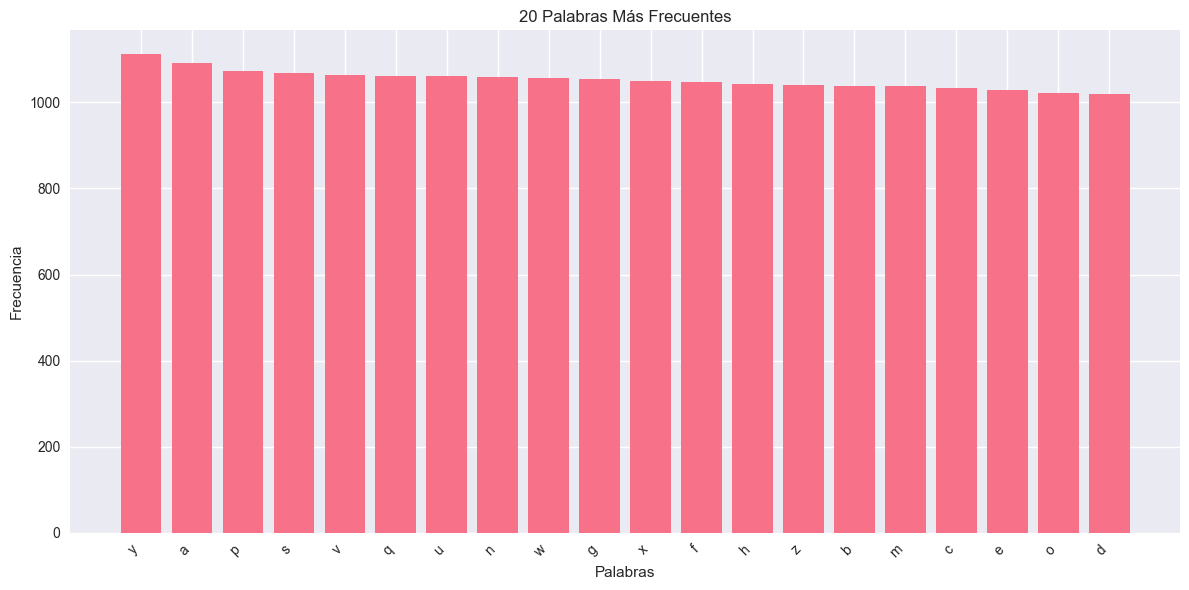

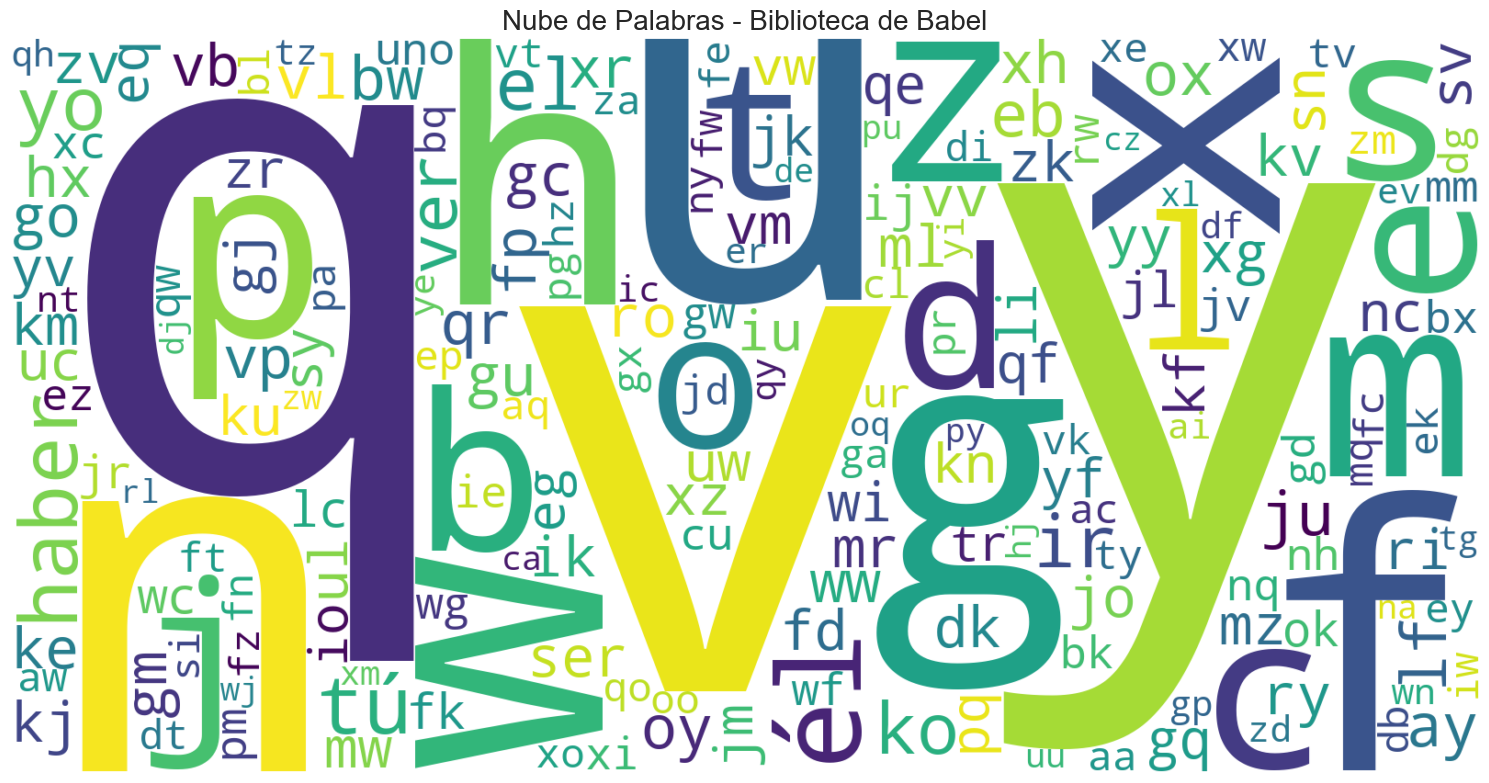

In [12]:
# ============================================
# 10. ANÁLISIS DE FRECUENCIAS
# ============================================
print("\n" + "="*50)
print("ANÁLISIS DE FRECUENCIAS")
print("="*50)

# Frecuencias globales (todos los documentos)
todas_las_palabras = [palabra for doc in documentos_lemmatizados for palabra in doc]
frecuencias = Counter(todas_las_palabras)

print(f"\nTotal de palabras únicas: {len(frecuencias)}")
print(f"\n20 palabras más frecuentes:")
for palabra, freq in frecuencias.most_common(20):
    print(f"  {palabra}: {freq}")

# Visualización: Gráfico de barras
plt.figure(figsize=(12, 6))
palabras, counts = zip(*frecuencias.most_common(20))
plt.bar(palabras, counts)
plt.xticks(rotation=45, ha='right')
plt.title('20 Palabras Más Frecuentes')
plt.xlabel('Palabras')
plt.ylabel('Frecuencia')
plt.tight_layout()
plt.show()

# WordCloud
plt.figure(figsize=(15, 8))
wordcloud = WordCloud(width=1600, height=800, 
                      background_color='white',
                      colormap='viridis').generate(' '.join(todas_las_palabras))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Nube de Palabras - Biblioteca de Babel', fontsize=20)
plt.tight_layout()
plt.show()




WORDCLOUD - PALABRAS MENOS FRECUENTES

Palabras con frecuencia 2-5: 7835
  Total palabras para WordCloud: 7835

✓ WordCloud guardado: wordcloud_babel_raras.png


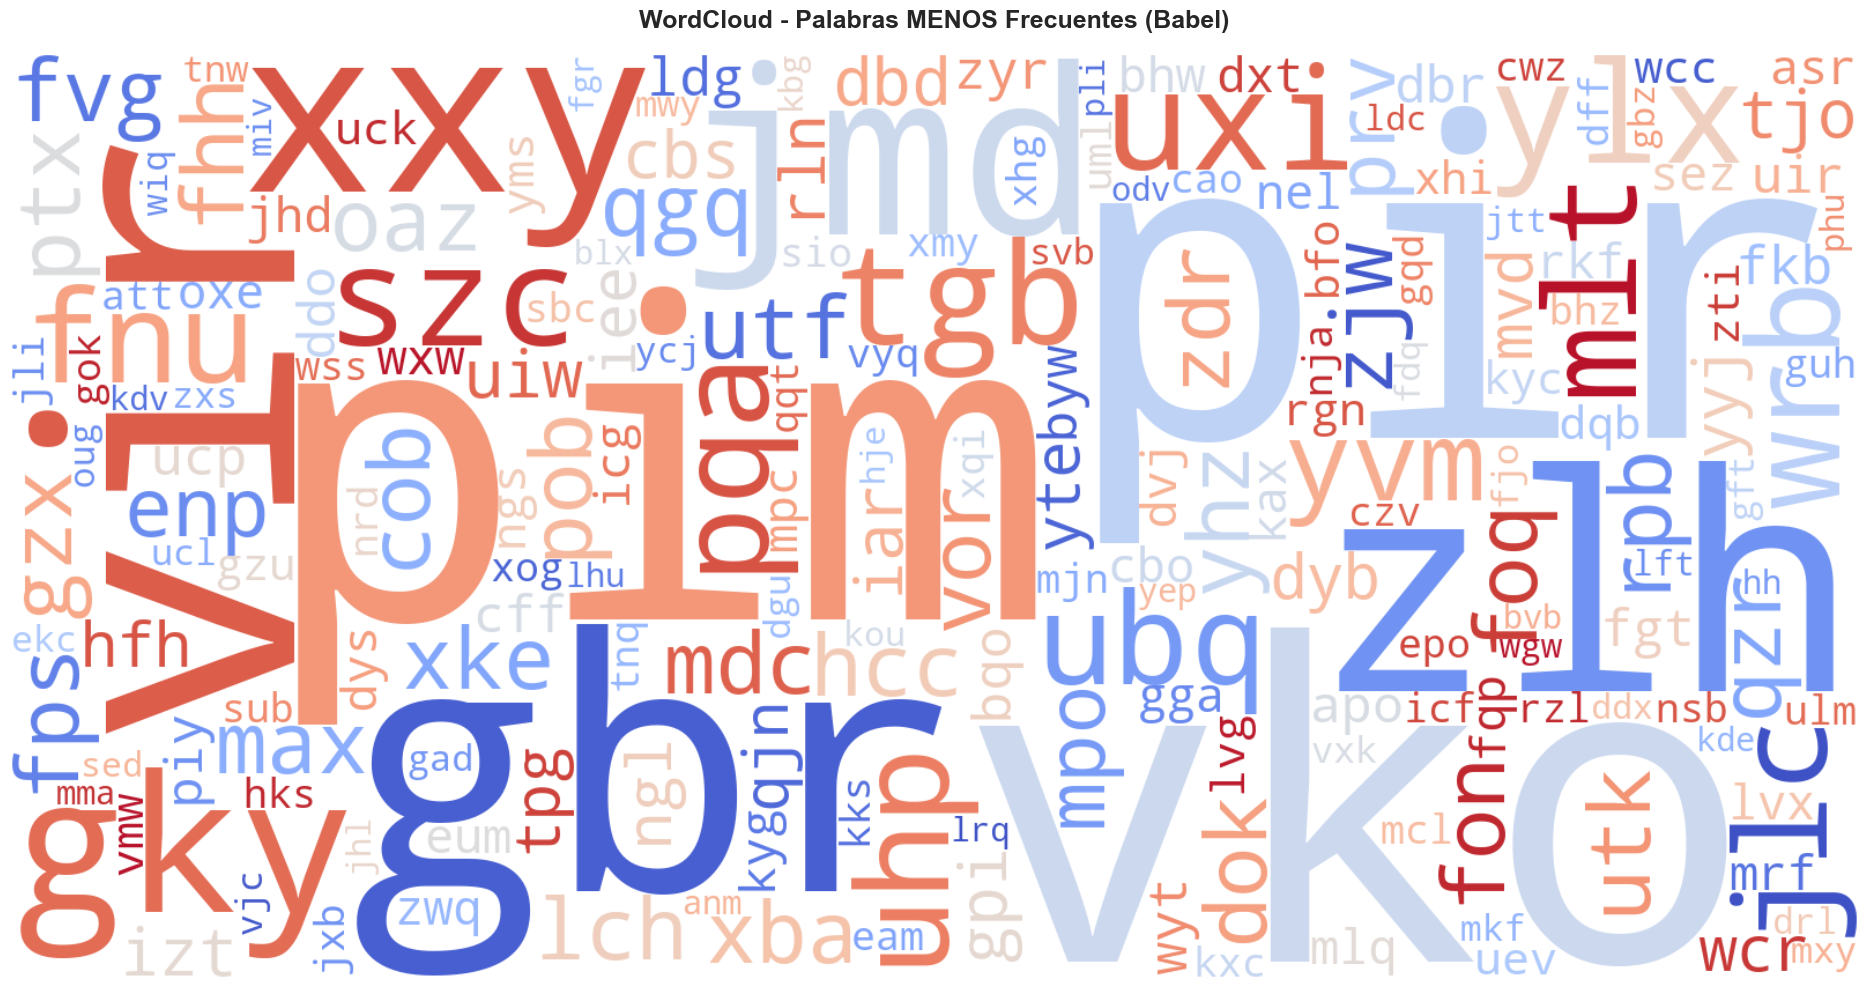


🔻 Ejemplos de palabras raras (primeras 30):
--------------------------------------------------
   1. tls                  → 2 veces
   2. kun                  → 2 veces
   3. eol                  → 2 veces
   4. hwe                  → 2 veces
   5. kqp                  → 2 veces
   6. qsa                  → 2 veces
   7. xynu                 → 2 veces
   8. nfv                  → 2 veces
   9. kynp                 → 2 veces
  10. tep                  → 2 veces
  11. vkv                  → 2 veces
  12. ual                  → 2 veces
  13. uri                  → 2 veces
  14. amu                  → 2 veces
  15. twjt                 → 2 veces
  16. sgw                  → 2 veces
  17. ngr                  → 2 veces
  18. rvj                  → 2 veces
  19. asb                  → 2 veces
  20. ozd                  → 2 veces
  21. gge                  → 2 veces
  22. ppm                  → 2 veces
  23. itr                  → 2 veces
  24. ttj                  → 2 veces
  25. lli       

In [14]:
# ============================================
# WORDCLOUD DE PALABRAS MENOS FRECUENTES
# ============================================
print("\n" + "="*50)
print("WORDCLOUD - PALABRAS MENOS FRECUENTES")
print("="*50)

from wordcloud import WordCloud
import matplotlib.pyplot as plt
import random

# Obtener palabras menos frecuentes (frecuencia 2-5)
palabras_raras = {palabra: freq for palabra, freq in frecuencias.items() 
                  if 2 <= freq <= 5}

print(f"\nPalabras con frecuencia 2-5: {len(palabras_raras)}")

# Si hay muy pocas, incluir hapax legomena (muestra)
if len(palabras_raras) < 50:
    print("  ⚠️ Pocas palabras en rango 2-5, incluyendo hapax...")
    hapax = {palabra: freq for palabra, freq in frecuencias.items() if freq == 1}
    hapax_muestra = dict(random.sample(list(hapax.items()), min(150, len(hapax))))
    palabras_raras.update(hapax_muestra)
    print(f"  Hapax añadidas: {len(hapax_muestra)}")

print(f"  Total palabras para WordCloud: {len(palabras_raras)}")

# Generar WordCloud de palabras raras
wordcloud_raras = WordCloud(
    width=1600, 
    height=800,
    background_color='white',
    colormap='coolwarm_r',  # Colormap invertido para diferenciarse
    max_words=200,
    relative_scaling=0.5,
    min_font_size=10
).generate_from_frequencies(palabras_raras)

plt.figure(figsize=(20, 10))
plt.imshow(wordcloud_raras, interpolation='bilinear')
plt.axis('off')
plt.title('WordCloud - Palabras MENOS Frecuentes (Babel)', 
          fontsize=18, fontweight='bold', pad=20)
plt.tight_layout()
plt.savefig('wordcloud_babel_raras.png', dpi=300, bbox_inches='tight')
print("\n✓ WordCloud guardado: wordcloud_babel_raras.png")
plt.show()

# Mostrar ejemplos
print(f"\n🔻 Ejemplos de palabras raras (primeras 30):")
print("-"*50)
ejemplos = sorted(palabras_raras.items(), key=lambda x: x[1])[:30]
for i, (palabra, freq) in enumerate(ejemplos, 1):
    print(f"  {i:2d}. {palabra:20s} → {freq} veces")
print("-"*50)


VECTORIZACIÓN

--- Bag of Words ---
Forma de la matriz BoW: (10, 100)
Características (primeras 20): ['am' 'ay' 'bw' 'bx' 'dg' 'di' 'dk' 'eb' 'el' 'eq' 'ez' 'fd' 'fk' 'fp'
 'ga' 'gc' 'gj' 'gm' 'go' 'gq']

Primeras filas de BoW:
       am  ay  bw  bx  dg  di  dk  eb  el  eq  ...  xh  xr  xz  yf  yo  yv  \
Doc_1   8   6   8   5   4  10   2   8   7   6  ...   8   5   5   4   5   4   
Doc_2  10   6   4   4   4   2   4   6   5   4  ...   4   5   3   0   8   2   
Doc_3   5   6   5   7   4   4   3   4   8   5  ...   6   4   4   4   7  10   
Doc_4   6   6   5   6   4   4   7   8  10   8  ...   2   3   5   6  12   3   
Doc_5   2   5   7   6   7   3   8   6  11   2  ...   6   5   5   4   5   4   

       yy  zk  zv  él  
Doc_1   4   5   3  20  
Doc_2   7   7   4  31  
Doc_3   3   3   4  22  
Doc_4   6   5   4  25  
Doc_5  10   5   9  25  

[5 rows x 100 columns]

--- TF-IDF ---
Forma de la matriz TF-IDF: (10, 100)

Primeras filas de TF-IDF:
             am        ay        bw        bx        d

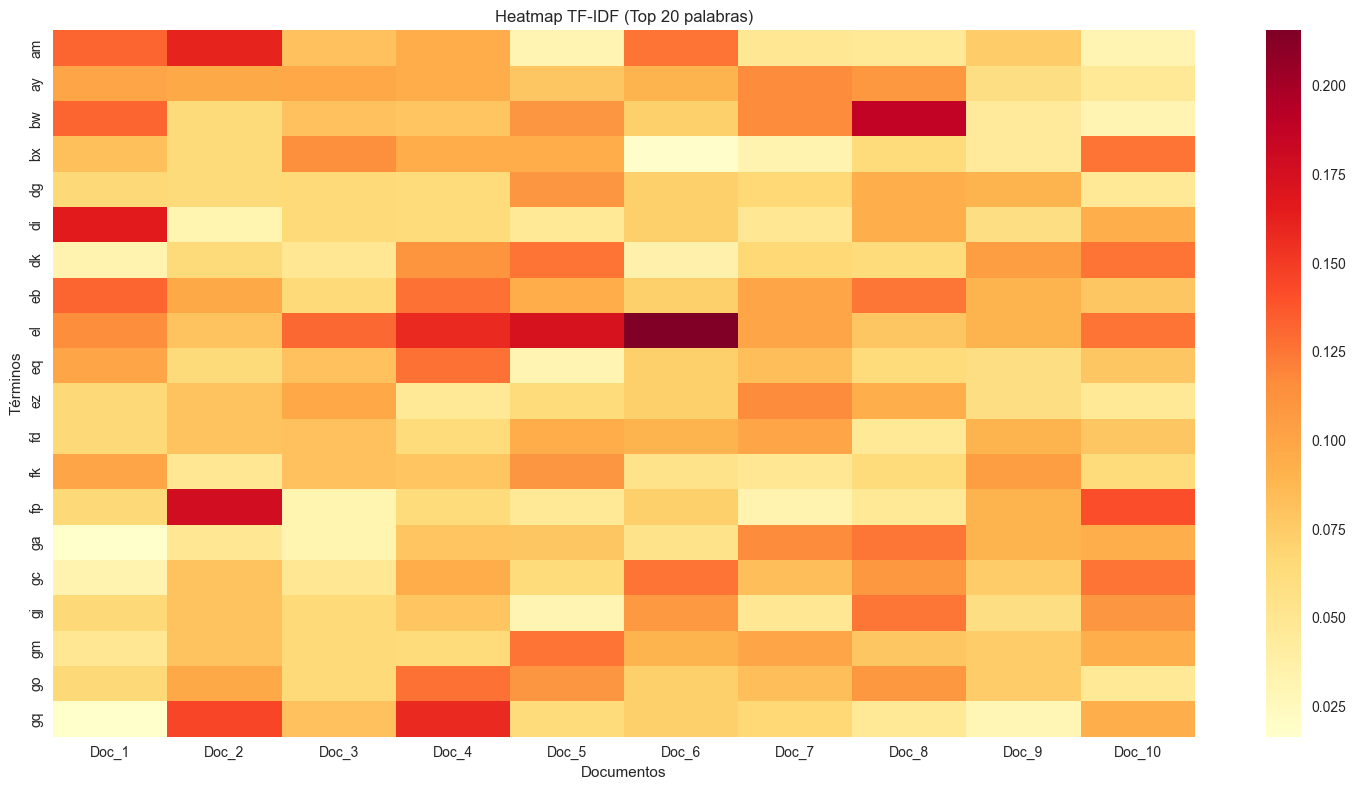

In [15]:
# ============================================
# 11. VECTORIZACIÓN
# ============================================
print("\n" + "="*50)
print("VECTORIZACIÓN")
print("="*50)

# Preparar textos para vectorización
textos_procesados = [' '.join(doc) for doc in documentos_lemmatizados]

# 11.1 Bag of Words (CountVectorizer)
print("\n--- Bag of Words ---")
vectorizer_bow = CountVectorizer(max_features=100)
bow_matrix = vectorizer_bow.fit_transform(textos_procesados)

print(f"Forma de la matriz BoW: {bow_matrix.shape}")
print(f"Características (primeras 20): {vectorizer_bow.get_feature_names_out()[:20]}")

# Convertir a DataFrame
df_bow = pd.DataFrame(bow_matrix.toarray(), 
                      columns=vectorizer_bow.get_feature_names_out(),
                      index=[f'Doc_{i+1}' for i in range(len(textos_procesados))])
print("\nPrimeras filas de BoW:")
print(df_bow.head())

# 11.2 TF-IDF
print("\n--- TF-IDF ---")
vectorizer_tfidf = TfidfVectorizer(max_features=100)
tfidf_matrix = vectorizer_tfidf.fit_transform(textos_procesados)

print(f"Forma de la matriz TF-IDF: {tfidf_matrix.shape}")

# Convertir a DataFrame
df_tfidf = pd.DataFrame(tfidf_matrix.toarray(), 
                        columns=vectorizer_tfidf.get_feature_names_out(),
                        index=[f'Doc_{i+1}' for i in range(len(textos_procesados))])
print("\nPrimeras filas de TF-IDF:")
print(df_tfidf.head())

# Palabras más importantes por documento (TF-IDF)
print("\nPalabras más relevantes por documento (Top 5):")
for i, doc_id in enumerate(df_tfidf.index):
    top_palabras = df_tfidf.loc[doc_id].nlargest(5)
    print(f"\n{doc_id}:")
    for palabra, score in top_palabras.items():
        print(f"  {palabra}: {score:.4f}")

# Visualización: Heatmap de TF-IDF
plt.figure(figsize=(15, 8))
sns.heatmap(df_tfidf.T.head(20), cmap='YlOrRd', annot=False)
plt.title('Heatmap TF-IDF (Top 20 palabras)')
plt.xlabel('Documentos')
plt.ylabel('Términos')
plt.tight_layout()
plt.show()



In [27]:
# ============================================
# TF-IDF COMPLETO (sin límite de features)
# Necesario para correlación y visualización 3D
# ============================================
print("\n--- TF-IDF Completo (todas las palabras) ---")
vectorizer_tfidf_completo = TfidfVectorizer()  # Sin max_features
tfidf_matrix_completo = vectorizer_tfidf_completo.fit_transform(textos_procesados)

df_tfidf_completo = pd.DataFrame(
    tfidf_matrix_completo.toarray(),
    columns=vectorizer_tfidf_completo.get_feature_names_out(),
    index=[f'Doc_{i+1}' for i in range(len(textos_procesados))]
)
print(f"Forma de df_tfidf_completo: {df_tfidf_completo.shape}")
print(f"Total de palabras únicas en corpus: {df_tfidf_completo.shape[1]}")


--- TF-IDF Completo (todas las palabras) ---
Forma de df_tfidf_completo: (10, 408841)
Total de palabras únicas en corpus: 408841



MAPA DE CORRELACIÓN ENTRE PALABRAS

Límite de palabras para análisis: 100
Matriz de correlación: (100, 100)

✓ Mapa guardado: correlacion_palabras_top100.png


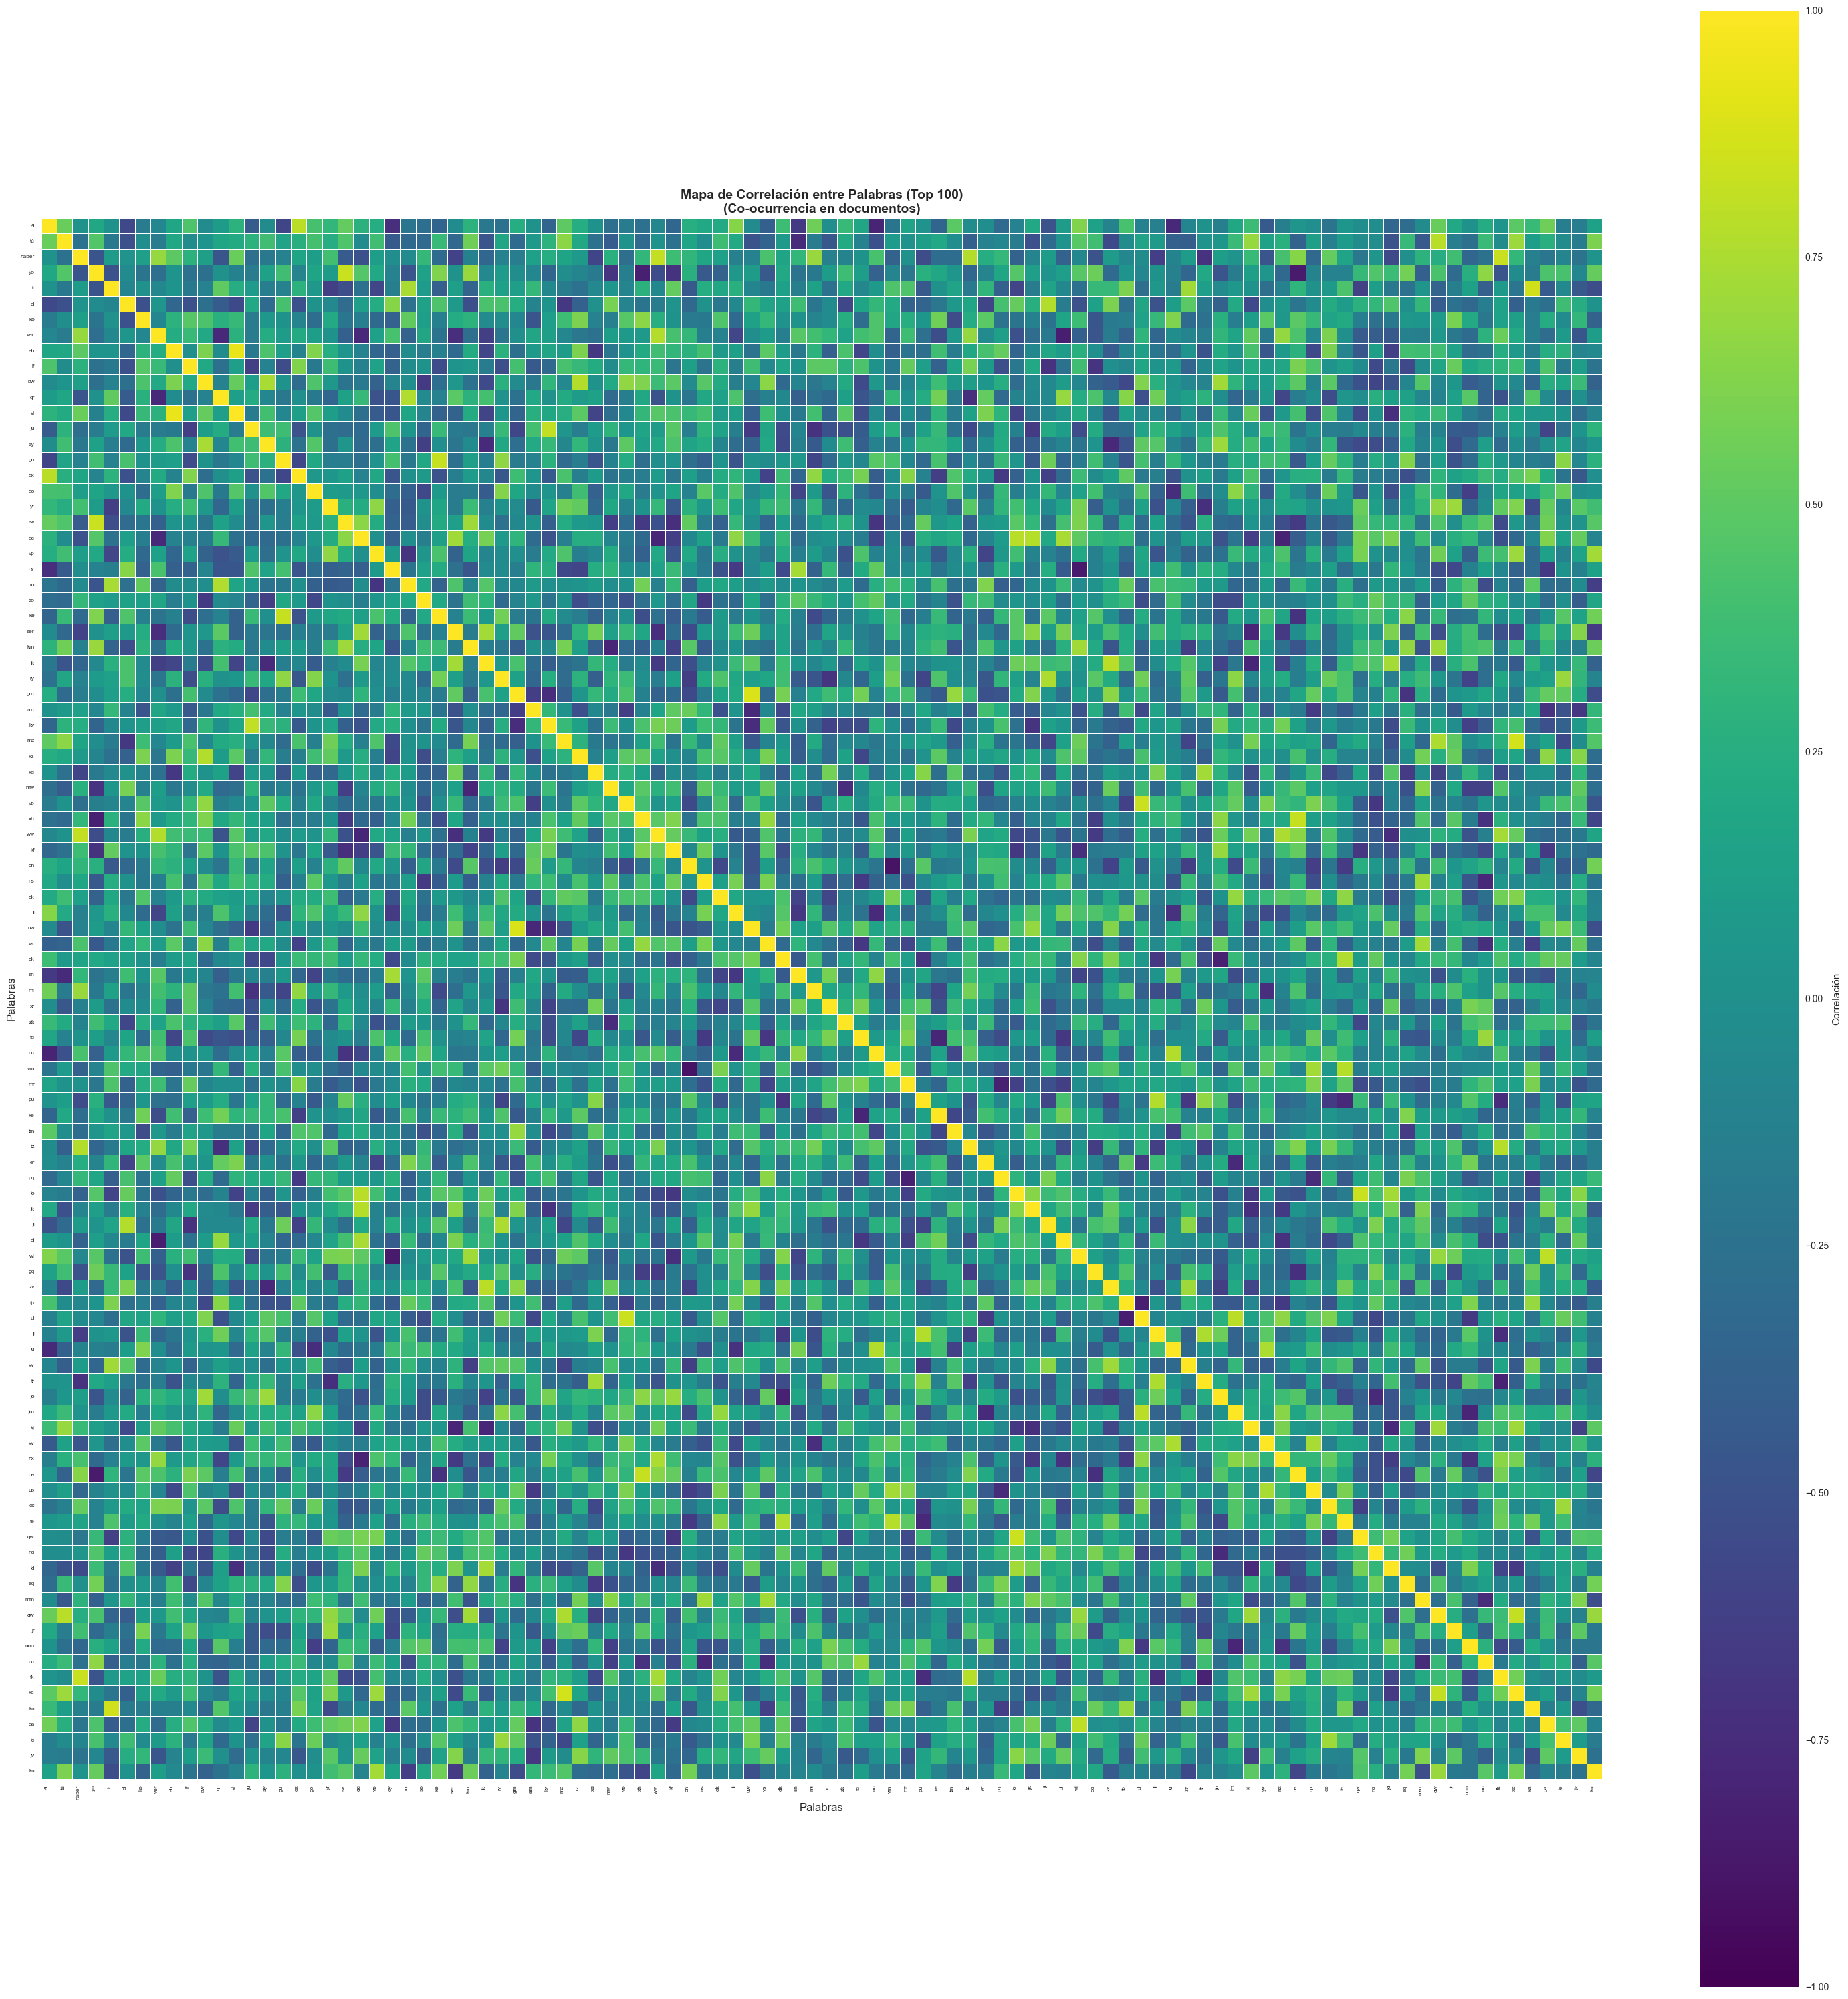

  ✓ correlacion_palabras_top100.csv

📊 Estadísticas:
  Correlación promedio: 0.003
  Correlación máxima: 0.931
  Correlación mínima: -0.899


In [30]:
# ============================================
# MAPA DE CORRELACIÓN ENTRE PALABRAS (AJUSTABLE)
# ============================================
print("\n" + "="*50)
print("MAPA DE CORRELACIÓN ENTRE PALABRAS")
print("="*50)

# ⚙️ PARÁMETRO AJUSTABLE
LIMITE_PALABRAS = 100  # <-- CAMBIA ESTE NÚMERO SEGÚN NECESITES

print(f"\nLímite de palabras para análisis: {LIMITE_PALABRAS}")

# Seleccionar las N palabras más frecuentes (por suma de TF-IDF)
top_palabras = df_tfidf_completo.sum().nlargest(LIMITE_PALABRAS).index
df_tfidf_seleccion = df_tfidf_completo[top_palabras]

# Calcular correlación entre palabras
correlacion_palabras = df_tfidf_seleccion.corr()

print(f"Matriz de correlación: {correlacion_palabras.shape}")

# Ajustar tamaño de figura según cantidad de palabras
fig_size = max(12, LIMITE_PALABRAS * 0.3)  # Escala automática

# Visualización
plt.figure(figsize=(fig_size, fig_size))

sns.heatmap(
    correlacion_palabras,
    cmap='viridis',
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={'label': 'Correlación'},
    xticklabels=True,
    yticklabels=True,
    vmin=-1,
    vmax=1
)

plt.title(f'Mapa de Correlación entre Palabras (Top {LIMITE_PALABRAS})\n(Co-ocurrencia en documentos)', 
          fontweight='bold', fontsize=14)
plt.xlabel('Palabras', fontsize=12)
plt.ylabel('Palabras', fontsize=12)
plt.xticks(rotation=90, ha='right', fontsize=max(6, 12 - LIMITE_PALABRAS//10))
plt.yticks(rotation=0, fontsize=max(6, 12 - LIMITE_PALABRAS//10))
plt.tight_layout()
plt.savefig(f'correlacion_palabras_top{LIMITE_PALABRAS}.png', dpi=300, bbox_inches='tight')
print(f"\n✓ Mapa guardado: correlacion_palabras_top{LIMITE_PALABRAS}.png")
plt.show()

# Exportar
correlacion_palabras.to_csv(f'correlacion_palabras_top{LIMITE_PALABRAS}.csv', encoding='utf-8-sig')
print(f"  ✓ correlacion_palabras_top{LIMITE_PALABRAS}.csv")

print("\n📊 Estadísticas:")
print(f"  Correlación promedio: {correlacion_palabras.values[np.triu_indices_from(correlacion_palabras.values, k=1)].mean():.3f}")
print(f"  Correlación máxima: {correlacion_palabras.values[np.triu_indices_from(correlacion_palabras.values, k=1)].max():.3f}")
print(f"  Correlación mínima: {correlacion_palabras.values[np.triu_indices_from(correlacion_palabras.values, k=1)].min():.3f}")


VISUALIZACIÓN 3D - PAISAJE DE CORRELACIÓN
Generando paisaje 3D para 100 palabras...

✓ Vista oceánica guardada: correlacion_3d_oceanico.png


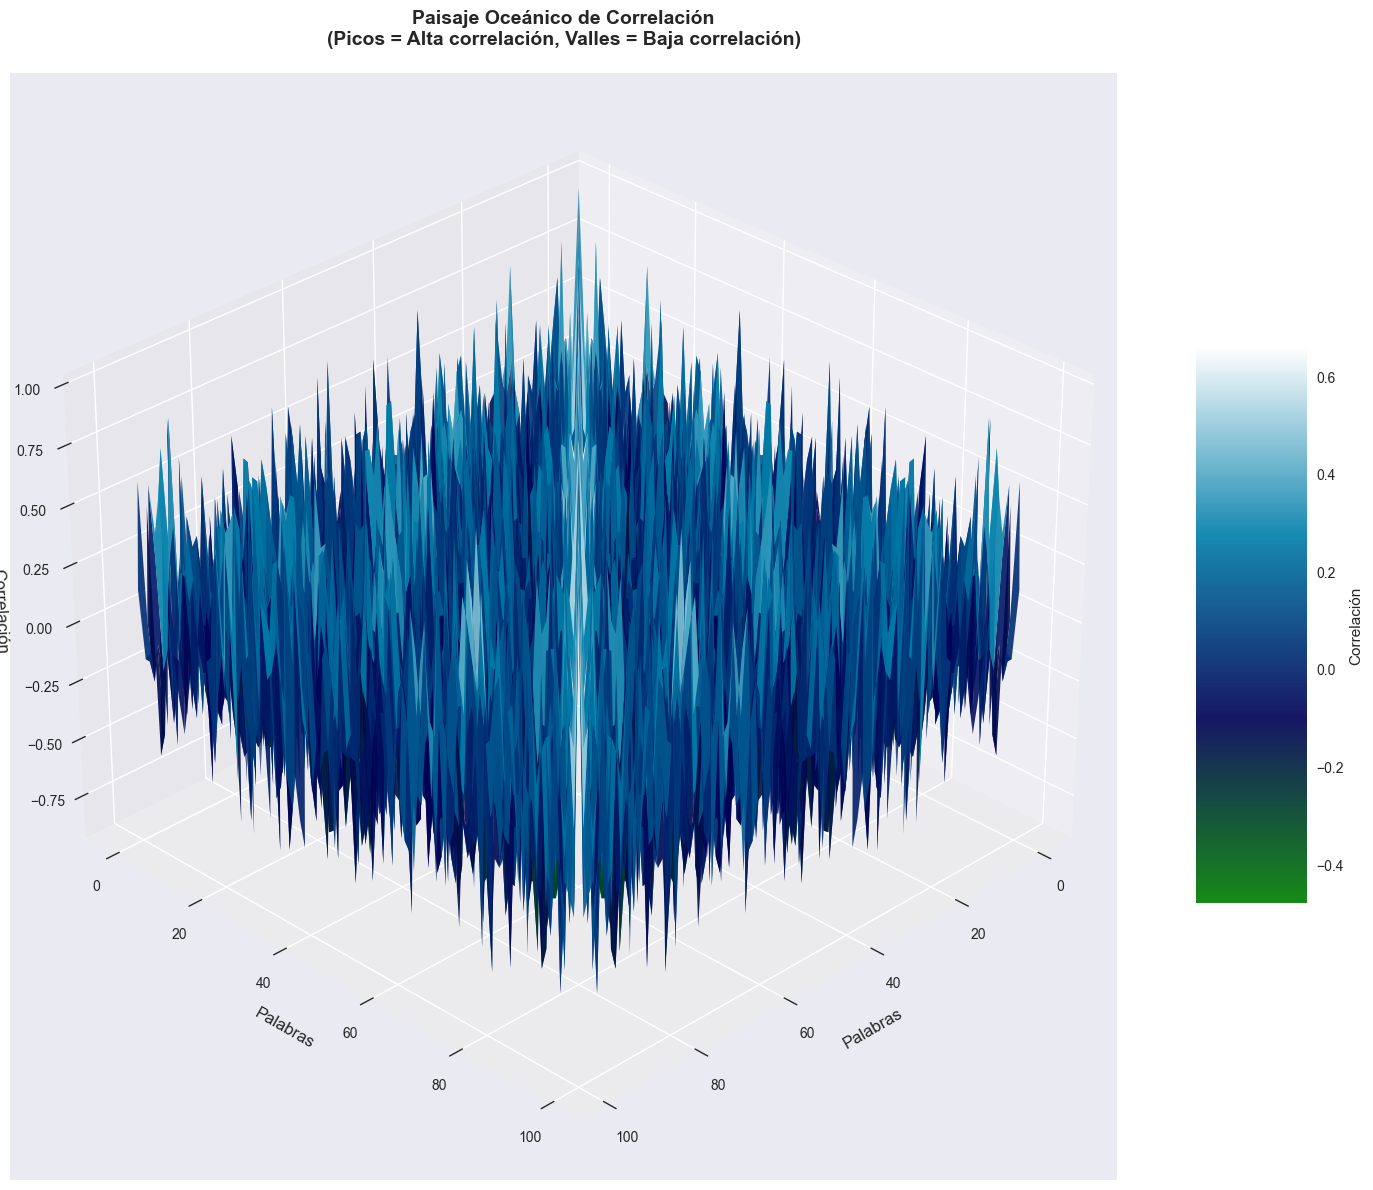

✓ Vista topográfica guardada: correlacion_3d_topografico.png


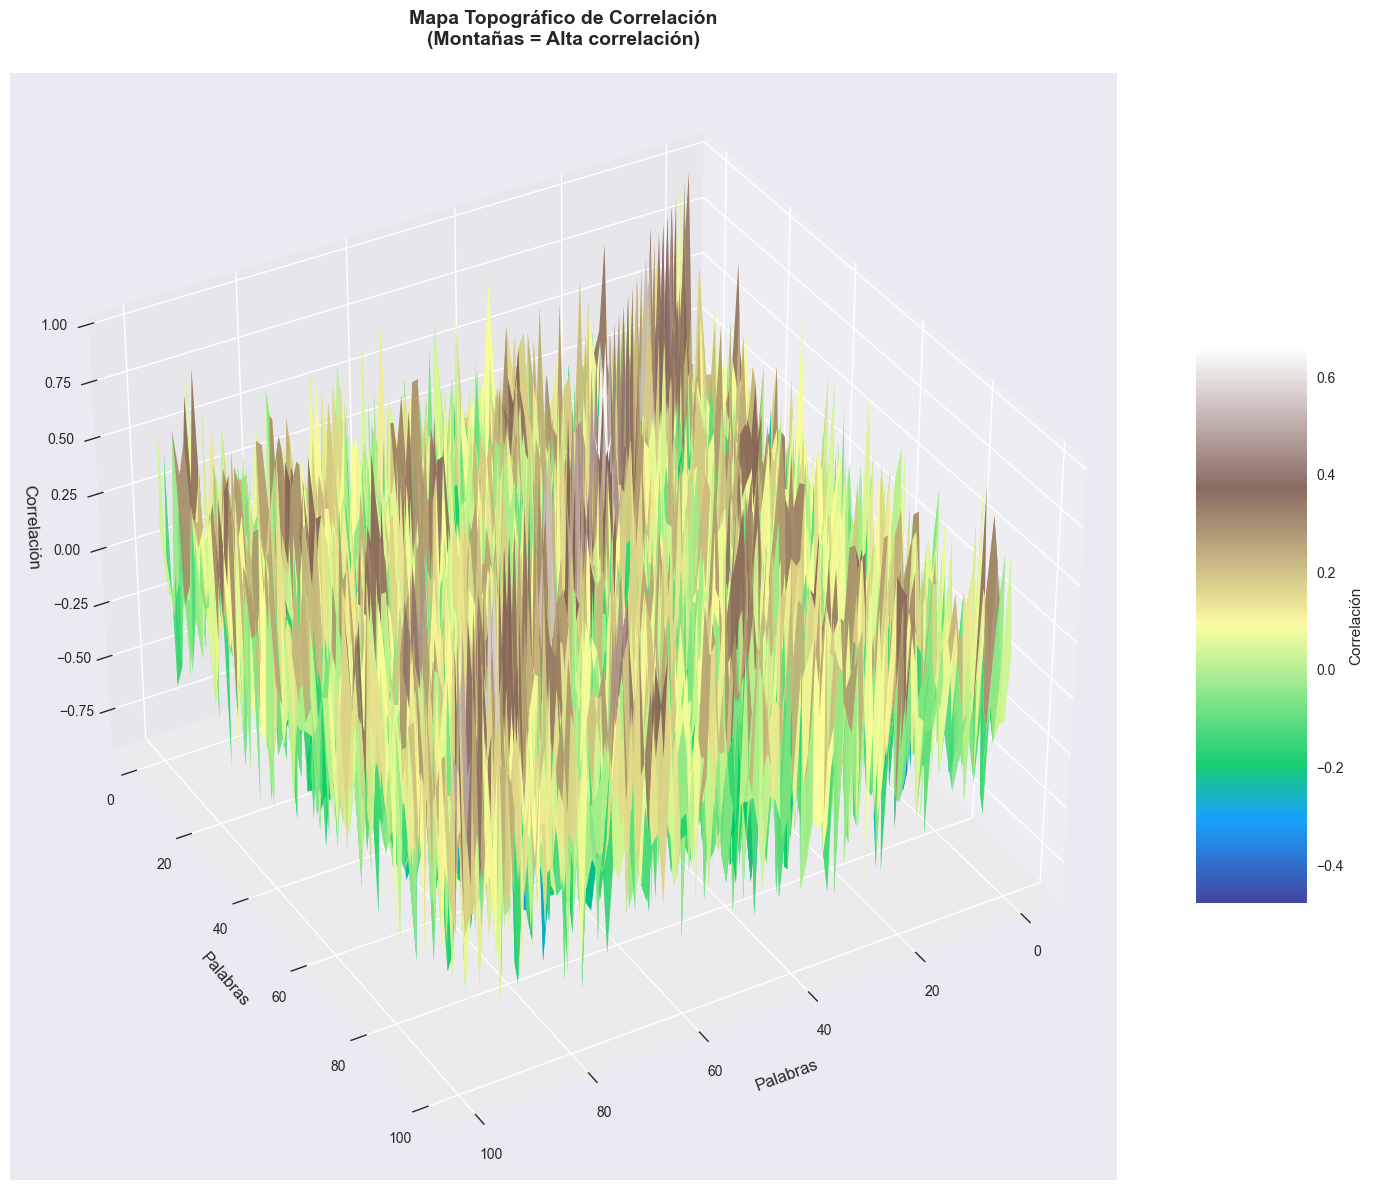

✓ Vista wireframe guardada: correlacion_3d_wireframe.png


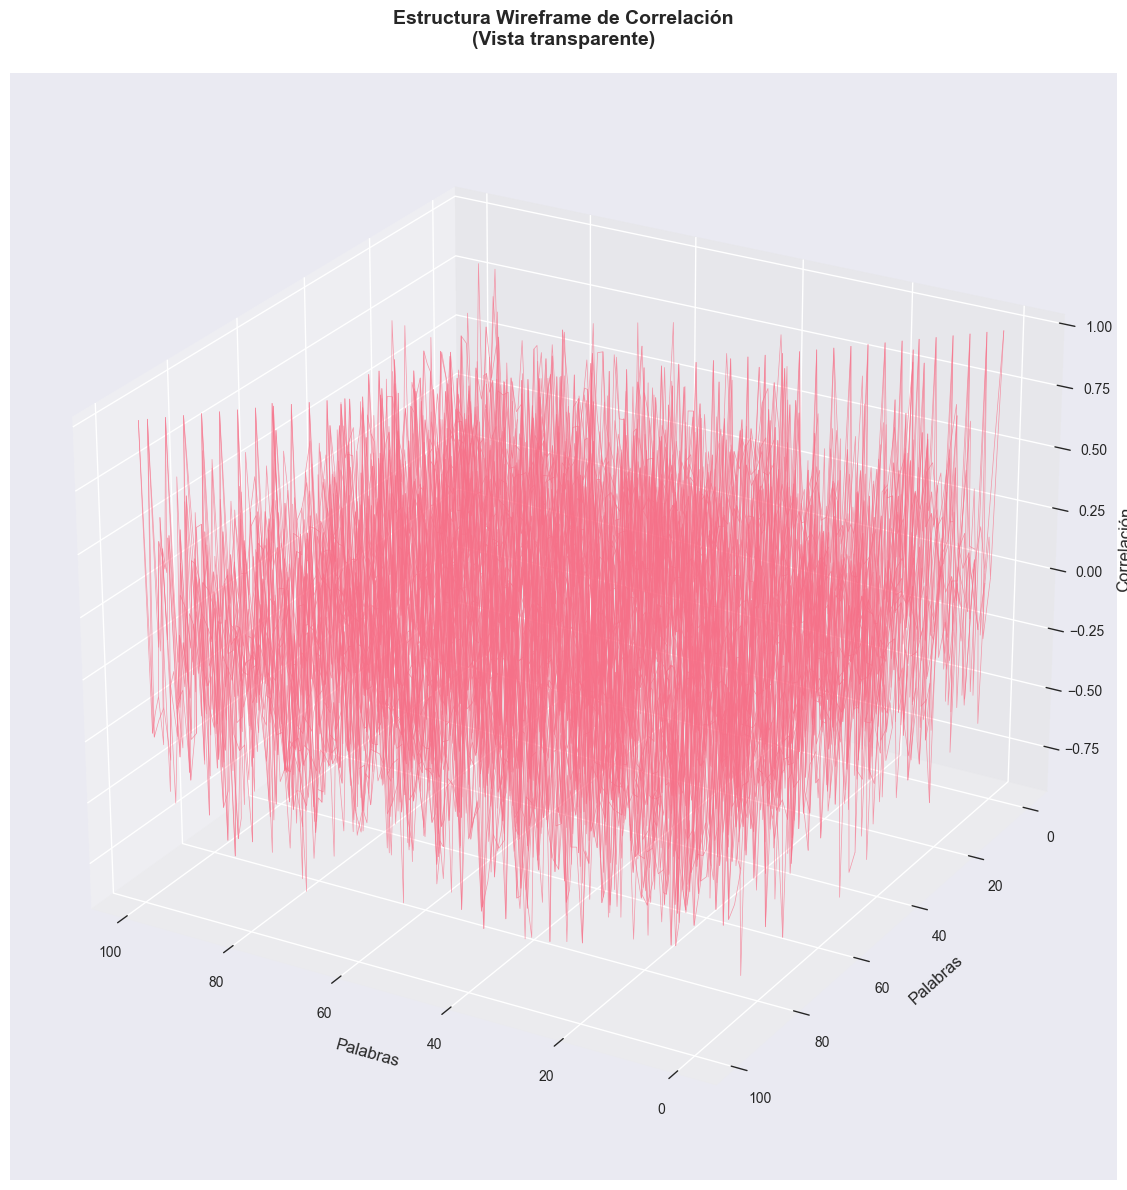

✓ Vista con contornos guardada: correlacion_3d_contornos.png


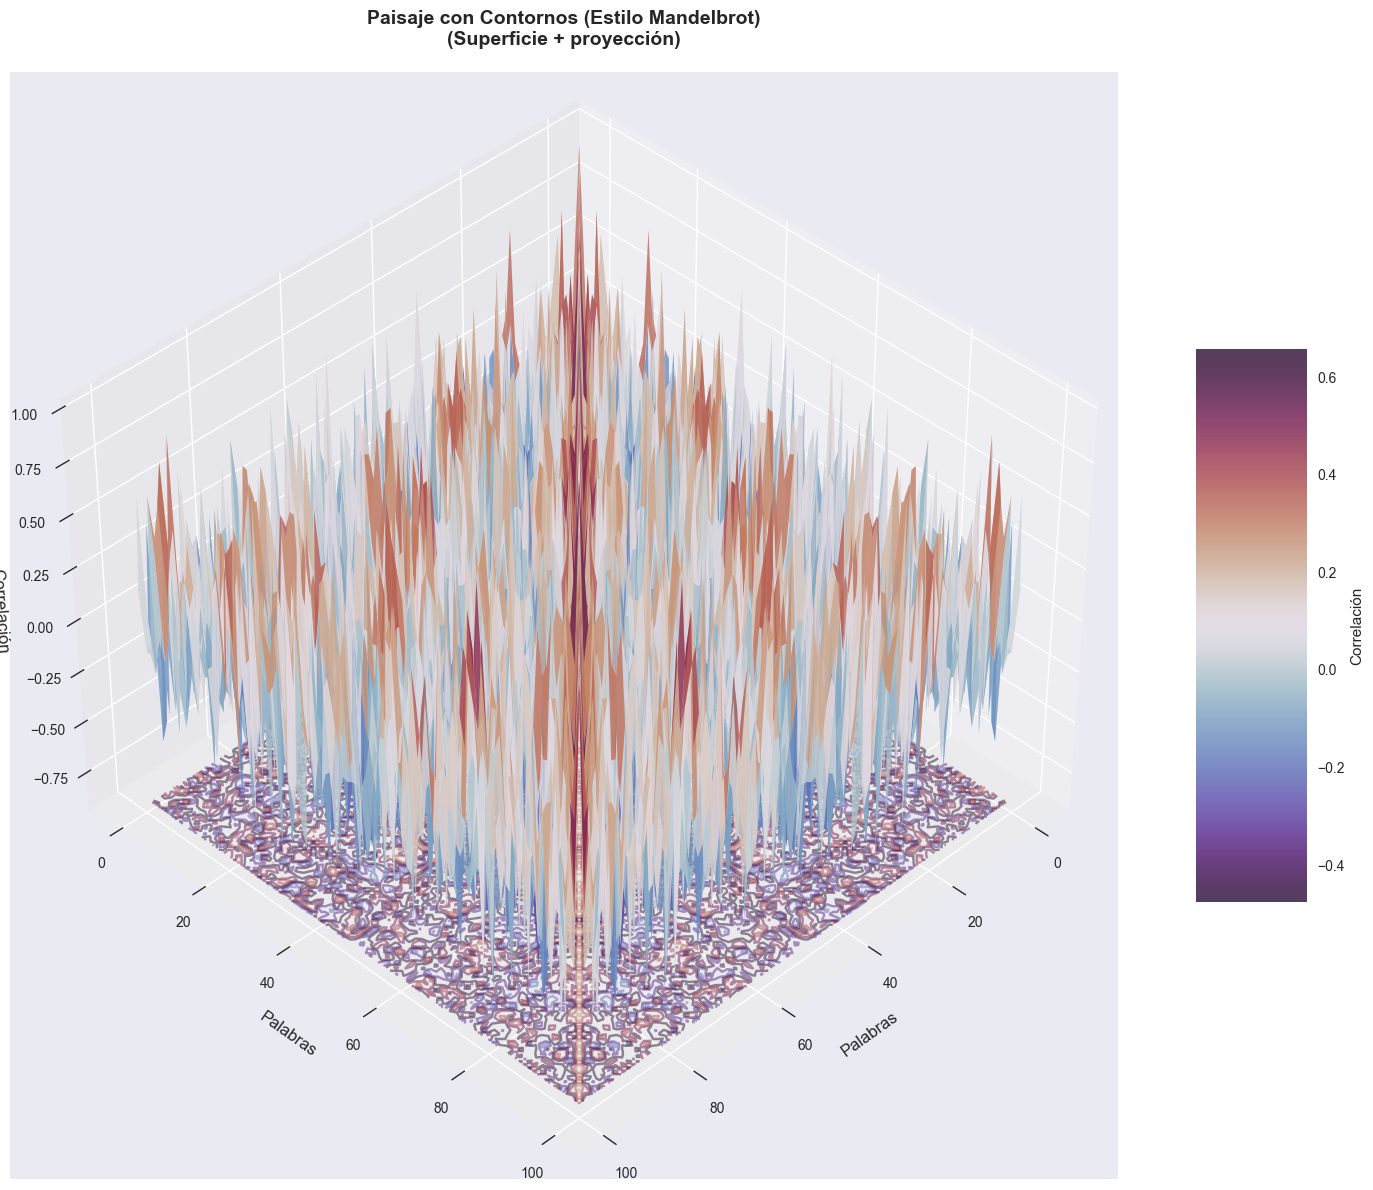

✓ Vista satelital guardada: correlacion_3d_satelital.png


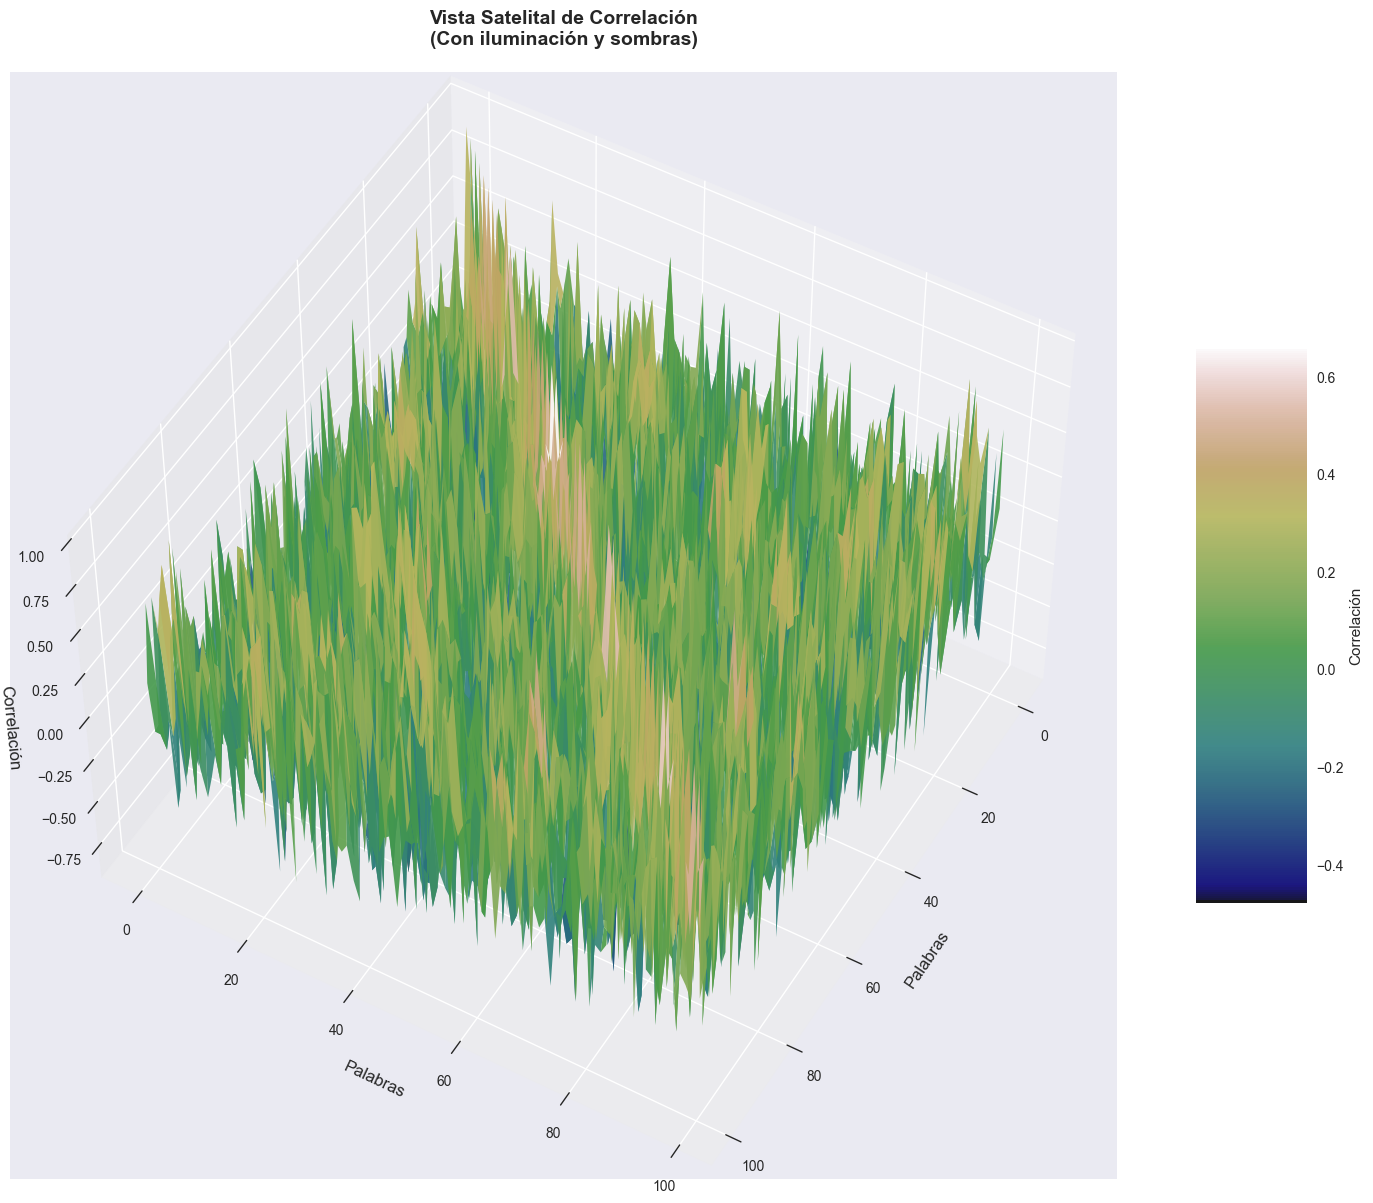


Generando rotación 360° (4 vistas)...
✓ Rotación 360° guardada: correlacion_3d_rotacion360.png


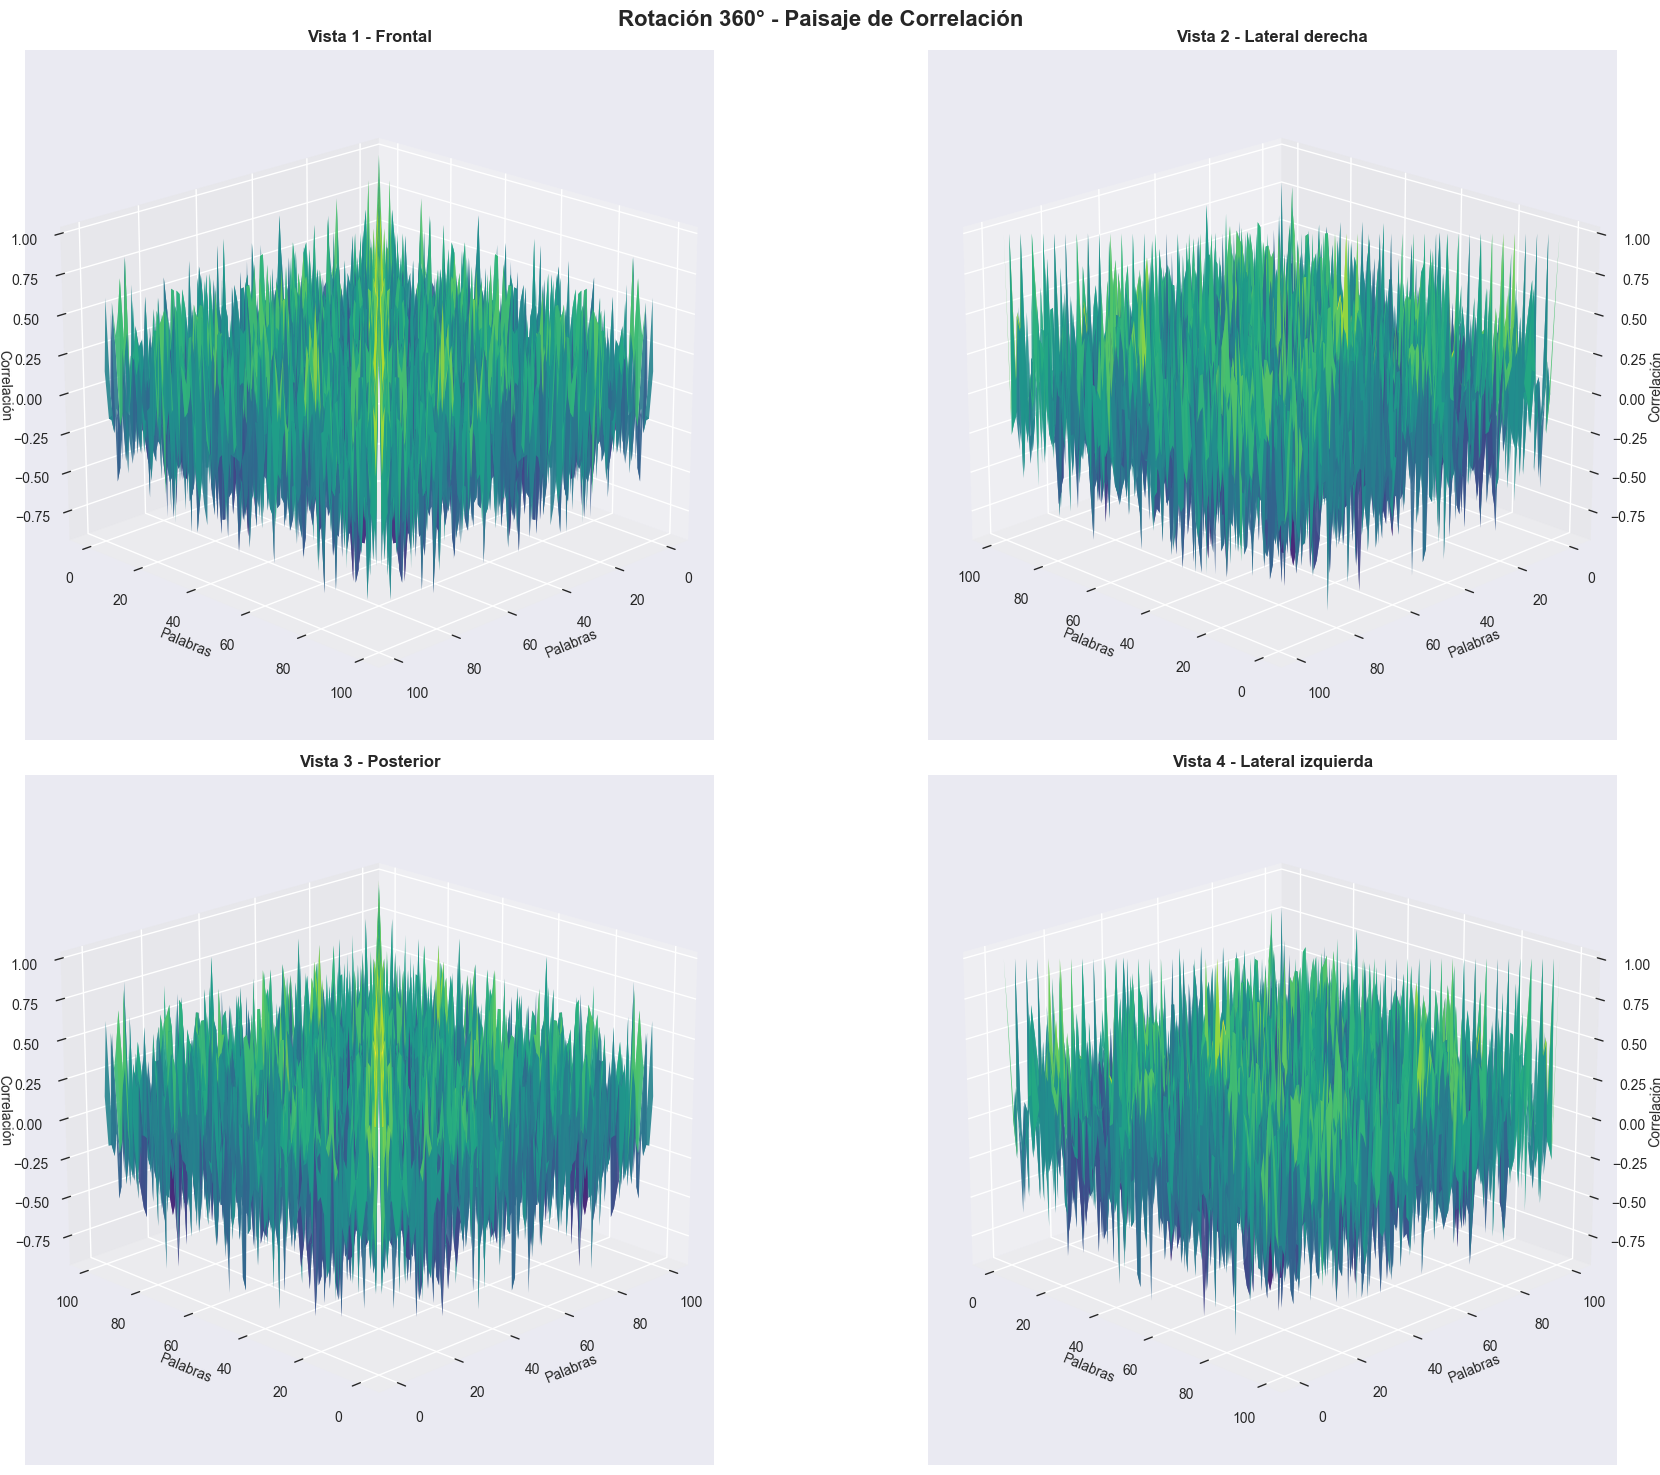


🎬 Generando animación interactiva...
Guardando animación (puede tardar 1-2 minutos)...
✓ Animación guardada: correlacion_3d_animacion.gif

📊 ANÁLISIS DE VOLUMEN Y TOPOGRAFÍA

🌊 Métricas del paisaje oceánico:
  Volumen bajo la superficie: 125.85
  Área de la base: 10000
  Pico más alto (correlación): 1.000
  Valle más profundo: -0.899
  Rugosidad (std): 0.344
  Rango vertical: 1.899

💡 Interpretación para Biblioteca de Babel:
  → Paisaje ONDULADO (rugosidad media)
  → Algunas correlaciones locales
  → Posible estructura emergente

⛰️ Picos detectados (correlación > 0.5): 676

💾 EXPORTANDO DATOS 3D
✓ Coordenadas 3D: correlacion_3d_coordenadas.csv
✓ Métricas del paisaje: correlacion_3d_metricas.csv

✅ VISUALIZACIÓN 3D COMPLETADA

Archivos generados:
  - 7 visualizaciones 3D (.png)
  - 1 animación rotativa (.gif)
  - 2 archivos de datos (.csv)

🌊 Concepto:
  El paisaje 3D representa la 'masa oceánica' de correlaciones.
  En textos aleatorios: océano PLANO (sin montañas/valles)
  En textos

C:\Users\diego.perezp\AppData\Local\Temp\ipykernel_12284\3480862777.py:240: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  volumen_total = np.trapz(np.trapz(Z, axis=1))


In [29]:
# ============================================
# VISUALIZACIÓN 3D - CORRELACIÓN COMO PAISAJE OCEÁNICO
# ============================================
print("\n" + "="*50)
print("VISUALIZACIÓN 3D - PAISAJE DE CORRELACIÓN")
print("="*50)

import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from matplotlib import cm

# ⚙️ PARÁMETROS
LIMITE_PALABRAS = 100  # Ajustable (50-100 funciona bien en 3D)

# Preparar datos
top_palabras = df_tfidf_completo.sum().nlargest(LIMITE_PALABRAS).index
df_tfidf_seleccion = df_tfidf_completo[top_palabras]
correlacion_palabras = df_tfidf_seleccion.corr()

print(f"Generando paisaje 3D para {LIMITE_PALABRAS} palabras...\n")

# Preparar meshgrid para 3D
X = np.arange(correlacion_palabras.shape[0])
Y = np.arange(correlacion_palabras.shape[1])
X, Y = np.meshgrid(X, Y)
Z = correlacion_palabras.values

# ============================================
# ESTILO 1: SUPERFICIE OCEÁNICA (ocean colormap)
# ============================================
fig = plt.figure(figsize=(16, 12))
ax = fig.add_subplot(111, projection='3d')

# Superficie 3D
surf = ax.plot_surface(X, Y, Z, cmap='ocean', 
                       linewidth=0, antialiased=True, 
                       alpha=0.9, edgecolor='none')

# Configuración
ax.set_xlabel('Palabras', fontsize=12, labelpad=10)
ax.set_ylabel('Palabras', fontsize=12, labelpad=10)
ax.set_zlabel('Correlación', fontsize=12, labelpad=10)
ax.set_title('Paisaje Oceánico de Correlación\n(Picos = Alta correlación, Valles = Baja correlación)', 
             fontsize=14, fontweight='bold', pad=20)

# Colorbar
fig.colorbar(surf, ax=ax, shrink=0.5, aspect=5, label='Correlación')

# Ángulo de vista
ax.view_init(elev=30, azim=45)

plt.tight_layout()
plt.savefig('correlacion_3d_oceanico.png', dpi=300, bbox_inches='tight')
print("✓ Vista oceánica guardada: correlacion_3d_oceanico.png")
plt.show()

# ============================================
# ESTILO 2: TOPOGRAFÍA (terrain colormap)
# ============================================
fig = plt.figure(figsize=(16, 12))
ax = fig.add_subplot(111, projection='3d')

surf = ax.plot_surface(X, Y, Z, cmap='terrain', 
                       linewidth=0, antialiased=True, 
                       alpha=0.9)

ax.set_xlabel('Palabras', fontsize=12, labelpad=10)
ax.set_ylabel('Palabras', fontsize=12, labelpad=10)
ax.set_zlabel('Correlación', fontsize=12, labelpad=10)
ax.set_title('Mapa Topográfico de Correlación\n(Montañas = Alta correlación)', 
             fontsize=14, fontweight='bold', pad=20)

fig.colorbar(surf, ax=ax, shrink=0.5, aspect=5, label='Correlación')
ax.view_init(elev=35, azim=60)

plt.tight_layout()
plt.savefig('correlacion_3d_topografico.png', dpi=300, bbox_inches='tight')
print("✓ Vista topográfica guardada: correlacion_3d_topografico.png")
plt.show()

# ============================================
# ESTILO 3: WIREFRAME (estructura transparente)
# ============================================
fig = plt.figure(figsize=(16, 12))
ax = fig.add_subplot(111, projection='3d')

# Wireframe con colores
wire = ax.plot_wireframe(X, Y, Z, cmap='coolwarm', 
                          linewidth=0.5, alpha=0.7)

ax.set_xlabel('Palabras', fontsize=12, labelpad=10)
ax.set_ylabel('Palabras', fontsize=12, labelpad=10)
ax.set_zlabel('Correlación', fontsize=12, labelpad=10)
ax.set_title('Estructura Wireframe de Correlación\n(Vista transparente)', 
             fontsize=14, fontweight='bold', pad=20)

ax.view_init(elev=25, azim=120)

plt.tight_layout()
plt.savefig('correlacion_3d_wireframe.png', dpi=300, bbox_inches='tight')
print("✓ Vista wireframe guardada: correlacion_3d_wireframe.png")
plt.show()

# ============================================
# ESTILO 4: CONTOUR 3D (estilo mandelbrot)
# ============================================
fig = plt.figure(figsize=(16, 12))
ax = fig.add_subplot(111, projection='3d')

# Superficie con contornos proyectados
surf = ax.plot_surface(X, Y, Z, cmap='twilight_shifted', ###############
                       linewidth=0, antialiased=True, alpha=0.8)

# Proyectar contornos en el plano inferior###
ax.contour(X, Y, Z, zdir='z', offset=Z.min(), cmap='twilight', alpha=0.5)#############

ax.set_xlabel('Palabras', fontsize=12, labelpad=10)
ax.set_ylabel('Palabras', fontsize=12, labelpad=10)
ax.set_zlabel('Correlación', fontsize=12, labelpad=10)
ax.set_title('Paisaje con Contornos (Estilo Mandelbrot)\n(Superficie + proyección)', 
             fontsize=14, fontweight='bold', pad=20)

fig.colorbar(surf, ax=ax, shrink=0.5, aspect=5, label='Correlación')
ax.view_init(elev=40, azim=45)

plt.tight_layout()
plt.savefig('correlacion_3d_contornos.png', dpi=300, bbox_inches='tight')
print("✓ Vista con contornos guardada: correlacion_3d_contornos.png")
plt.show()

# ============================================
# ESTILO 5: VISTA AÉREA CON SOMBRAS (dramatic)
# ============================================
fig = plt.figure(figsize=(16, 12))
ax = fig.add_subplot(111, projection='3d')

# Superficie con sombreado
surf = ax.plot_surface(X, Y, Z, cmap='gist_earth', 
                       linewidth=0, antialiased=True, 
                       shade=True, alpha=0.9)

ax.set_xlabel('Palabras', fontsize=12, labelpad=10)
ax.set_ylabel('Palabras', fontsize=12, labelpad=10)
ax.set_zlabel('Correlación', fontsize=12, labelpad=10)
ax.set_title('Vista Satelital de Correlación\n(Con iluminación y sombras)', 
             fontsize=14, fontweight='bold', pad=20)

fig.colorbar(surf, ax=ax, shrink=0.5, aspect=5, label='Correlación')
ax.view_init(elev=50, azim=30)

# Iluminación
from matplotlib.colors import LightSource
ls = LightSource(azdeg=315, altdeg=45)
illuminated = ls.shade(Z, cmap=cm.gist_earth, blend_mode='soft')

plt.tight_layout()
plt.savefig('correlacion_3d_satelital.png', dpi=300, bbox_inches='tight')
print("✓ Vista satelital guardada: correlacion_3d_satelital.png")
plt.show()

# ============================================
# ESTILO 6: MÚLTIPLES ÁNGULOS (rotación 360°)
# ============================================
print("\nGenerando rotación 360° (4 vistas)...")

angulos = [
    (20, 45, 'Vista 1 - Frontal'),
    (20, 135, 'Vista 2 - Lateral derecha'),
    (20, 225, 'Vista 3 - Posterior'),
    (20, 315, 'Vista 4 - Lateral izquierda')
]

fig = plt.figure(figsize=(20, 15))

for idx, (elev, azim, titulo) in enumerate(angulos, 1):
    ax = fig.add_subplot(2, 2, idx, projection='3d')
    
    surf = ax.plot_surface(X, Y, Z, cmap='viridis', 
                           linewidth=0, antialiased=True, alpha=0.9)
    
    ax.set_xlabel('Palabras', fontsize=10)
    ax.set_ylabel('Palabras', fontsize=10)
    ax.set_zlabel('Correlación', fontsize=10)
    ax.set_title(titulo, fontsize=12, fontweight='bold')
    ax.view_init(elev=elev, azim=azim)

plt.suptitle('Rotación 360° - Paisaje de Correlación', 
             fontsize=16, fontweight='bold', y=0.98)
plt.tight_layout()
plt.savefig('correlacion_3d_rotacion360.png', dpi=300, bbox_inches='tight')
print("✓ Rotación 360° guardada: correlacion_3d_rotacion360.png")
plt.show()

# ============================================
# ESTILO 7: ANIMACIÓN INTERACTIVA (para notebook)
# ============================================
print("\n🎬 Generando animación interactiva...")

from matplotlib.animation import FuncAnimation
from IPython.display import HTML

fig = plt.figure(figsize=(12, 10))
ax = fig.add_subplot(111, projection='3d')

def update(frame):
    ax.clear()
    surf = ax.plot_surface(X, Y, Z, cmap='ocean', 
                           linewidth=0, antialiased=True, alpha=0.9)
    ax.set_xlabel('Palabras')
    ax.set_ylabel('Palabras')
    ax.set_zlabel('Correlación')
    ax.set_title(f'Paisaje Oceánico de Correlación\nÁngulo: {frame}°', 
                 fontweight='bold')
    ax.view_init(elev=30, azim=frame)
    return surf,

# Crear animación (360° en 72 frames)
anim = FuncAnimation(fig, update, frames=np.arange(0, 360, 5), 
                     interval=100, blit=False)

# Guardar como GIF
print("Guardando animación (puede tardar 1-2 minutos)...")
anim.save('correlacion_3d_animacion.gif', writer='pillow', fps=10, dpi=100)
print("✓ Animación guardada: correlacion_3d_animacion.gif")

plt.close()

# Mostrar en notebook (si estás en Jupyter)
# HTML(anim.to_jshtml())

# ============================================
# ANÁLISIS DE "VOLUMEN OCEÁNICO"
# ============================================
print("\n" + "="*50)
print("📊 ANÁLISIS DE VOLUMEN Y TOPOGRAFÍA")
print("="*50)

# Calcular métricas del "paisaje"
volumen_total = np.trapz(np.trapz(Z, axis=1))
area_superficie = Z.shape[0] * Z.shape[1]
altura_maxima = Z.max()
profundidad_minima = Z.min()
rugosidad = np.std(Z)  # Desviación estándar como medida de rugosidad

print(f"\n🌊 Métricas del paisaje oceánico:")
print(f"  Volumen bajo la superficie: {volumen_total:.2f}")
print(f"  Área de la base: {area_superficie}")
print(f"  Pico más alto (correlación): {altura_maxima:.3f}")
print(f"  Valle más profundo: {profundidad_minima:.3f}")
print(f"  Rugosidad (std): {rugosidad:.3f}")
print(f"  Rango vertical: {altura_maxima - profundidad_minima:.3f}")

# Interpretación para textos aleatorios
print(f"\n💡 Interpretación para Biblioteca de Babel:")
if rugosidad < 0.2:
    print("  → Paisaje PLANO (baja rugosidad)")
    print("  → Correlaciones uniformemente bajas")
    print("  → Consistente con aleatoriedad genuina")
elif rugosidad < 0.4:
    print("  → Paisaje ONDULADO (rugosidad media)")
    print("  → Algunas correlaciones locales")
    print("  → Posible estructura emergente")
else:
    print("  → Paisaje MONTAÑOSO (alta rugosidad)")
    print("  → Correlaciones fuertes presentes")
    print("  → Estructura lingüística clara")

# Contar "picos" (correlaciones altas)
umbral_pico = 0.5
picos = np.sum(Z > umbral_pico) - Z.shape[0]  # Excluir diagonal
print(f"\n⛰️ Picos detectados (correlación > {umbral_pico}): {picos}")

if picos == 0:
    print("  → Sin picos significativos (océano calmo)")
    print("  → Texto verdaderamente aleatorio")

# ============================================
# EXPORTAR DATOS 3D
# ============================================
print("\n" + "="*50)
print("💾 EXPORTANDO DATOS 3D")
print("="*50)

# Guardar coordenadas 3D para uso externo
datos_3d = pd.DataFrame({
    'X': X.flatten(),
    'Y': Y.flatten(),
    'Z': Z.flatten(),
    'Palabra_X': [top_palabras[int(i)] for i in X.flatten()],
    'Palabra_Y': [top_palabras[int(i)] for i in Y.flatten()]
})

datos_3d.to_csv('correlacion_3d_coordenadas.csv', index=False, encoding='utf-8-sig')
print("✓ Coordenadas 3D: correlacion_3d_coordenadas.csv")

# Resumen
resumen_3d = pd.DataFrame({
    'Métrica': ['Volumen', 'Área Base', 'Pico Máximo', 'Valle Mínimo', 
                'Rugosidad', 'Rango Vertical', 'Picos (>0.5)'],
    'Valor': [volumen_total, area_superficie, altura_maxima, profundidad_minima,
              rugosidad, altura_maxima - profundidad_minima, picos]
})

resumen_3d.to_csv('correlacion_3d_metricas.csv', index=False, encoding='utf-8-sig')
print("✓ Métricas del paisaje: correlacion_3d_metricas.csv")

print("\n" + "="*50)
print("✅ VISUALIZACIÓN 3D COMPLETADA")
print("="*50)
print(f"\nArchivos generados:")
print(f"  - 7 visualizaciones 3D (.png)")
print(f"  - 1 animación rotativa (.gif)")
print(f"  - 2 archivos de datos (.csv)")

print(f"\n🌊 Concepto:")
print(f"  El paisaje 3D representa la 'masa oceánica' de correlaciones.")
print(f"  En textos aleatorios: océano PLANO (sin montañas/valles)")
print(f"  En textos con significado: paisaje ACCIDENTADO (patrones claros)")


ANÁLISIS DE SENTIMIENTOS

Doc_1:
  Polaridad: 0.486
  Subjetividad: 0.543
  Clasificación: Positivo

Doc_2:
  Polaridad: 0.158
  Subjetividad: 0.436
  Clasificación: Positivo

Doc_3:
  Polaridad: 0.321
  Subjetividad: 0.437
  Clasificación: Positivo

Doc_4:
  Polaridad: 0.313
  Subjetividad: 0.618
  Clasificación: Positivo

Doc_5:
  Polaridad: 0.362
  Subjetividad: 0.486
  Clasificación: Positivo

Doc_6:
  Polaridad: 0.044
  Subjetividad: 0.719
  Clasificación: Neutral

Doc_7:
  Polaridad: 0.414
  Subjetividad: 0.543
  Clasificación: Positivo

Doc_8:
  Polaridad: 0.293
  Subjetividad: 0.524
  Clasificación: Positivo

Doc_9:
  Polaridad: 0.356
  Subjetividad: 0.478
  Clasificación: Positivo

Doc_10:
  Polaridad: 0.400
  Subjetividad: 0.610
  Clasificación: Positivo

Resumen de Sentimientos:
  Documento  Polaridad  Subjetividad Clasificación
0     Doc_1   0.485714      0.542857      Positivo
1     Doc_2   0.158333      0.436111      Positivo
2     Doc_3   0.321053      0.436842      Pos

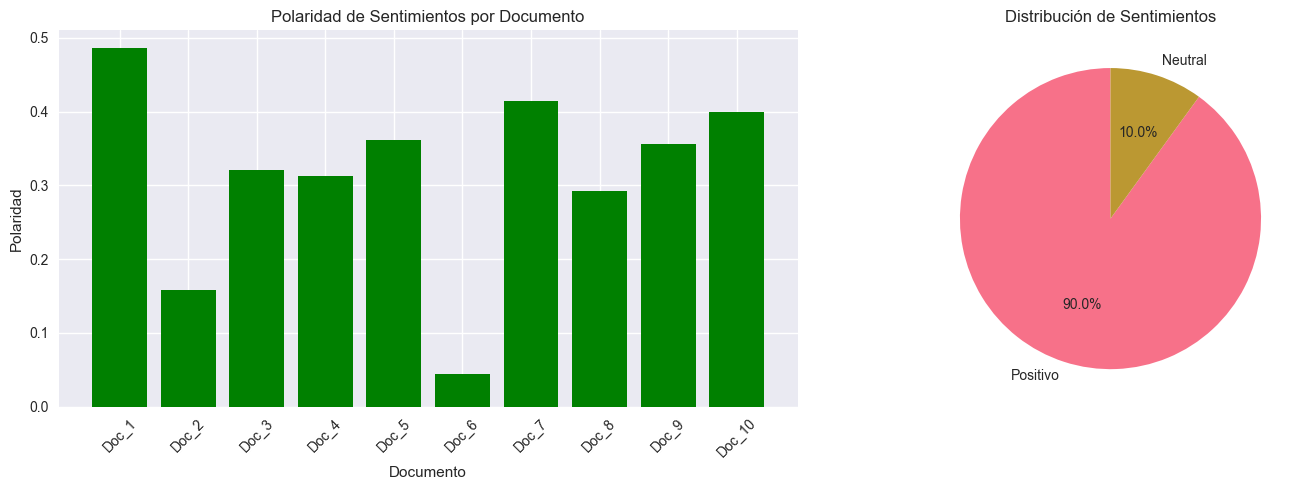

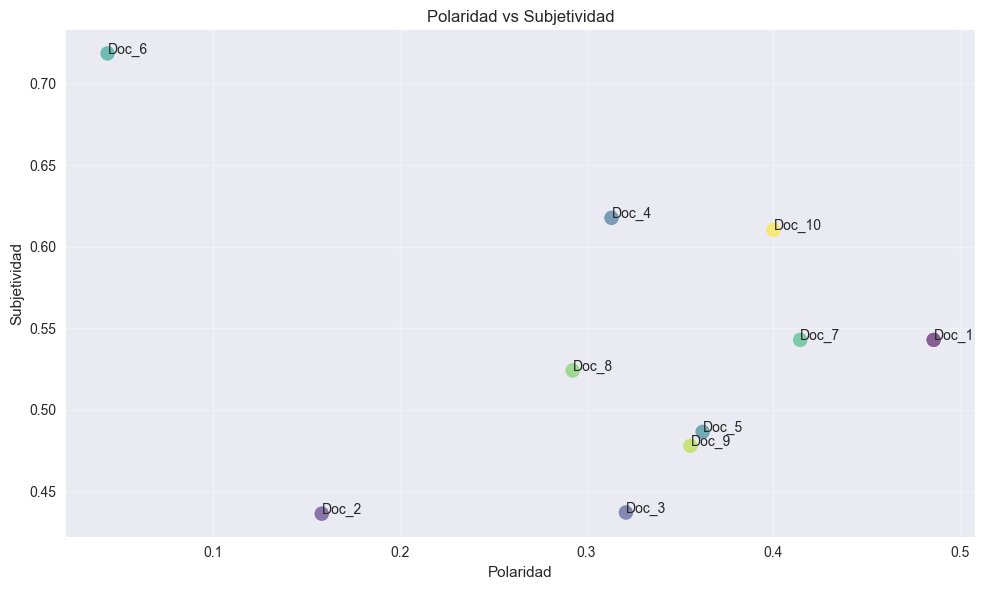

In [20]:
# ============================================
# 12. ANÁLISIS DE SENTIMIENTOS
# ============================================
print("\n" + "="*50)
print("ANÁLISIS DE SENTIMIENTOS")
print("="*50)

# Análisis con TextBlob
sentimientos = []

for i, doc in enumerate(documentos_limpios, 1):
    blob = TextBlob(doc)
    polaridad = blob.sentiment.polarity
    subjetividad = blob.sentiment.subjectivity
    
    # Clasificar sentimiento
    if polaridad > 0.1:
        clasificacion = 'Positivo'
    elif polaridad < -0.1:
        clasificacion = 'Negativo'
    else:
        clasificacion = 'Neutral'
    
    sentimientos.append({
        'Documento': f'Doc_{i}',
        'Polaridad': polaridad,
        'Subjetividad': subjetividad,
        'Clasificación': clasificacion
    })
    
    print(f"\nDoc_{i}:")
    print(f"  Polaridad: {polaridad:.3f}")
    print(f"  Subjetividad: {subjetividad:.3f}")
    print(f"  Clasificación: {clasificacion}")

# DataFrame de sentimientos
df_sentimientos = pd.DataFrame(sentimientos)
print("\nResumen de Sentimientos:")
print(df_sentimientos)

# Visualización de sentimientos
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Gráfico 1: Polaridad
axes[0].bar(df_sentimientos['Documento'], df_sentimientos['Polaridad'], 
            color=['green' if x > 0 else 'red' if x < 0 else 'gray' 
                   for x in df_sentimientos['Polaridad']])
axes[0].axhline(y=0, color='black', linestyle='--', linewidth=0.5)
axes[0].set_title('Polaridad de Sentimientos por Documento')
axes[0].set_xlabel('Documento')
axes[0].set_ylabel('Polaridad')
axes[0].tick_params(axis='x', rotation=45)

# Gráfico 2: Distribución de clasificaciones
clasificacion_counts = df_sentimientos['Clasificación'].value_counts()
axes[1].pie(clasificacion_counts, labels=clasificacion_counts.index, 
            autopct='%1.1f%%', startangle=90)
axes[1].set_title('Distribución de Sentimientos')

plt.tight_layout()
plt.show()

# Scatter plot: Polaridad vs Subjetividad
plt.figure(figsize=(10, 6))
plt.scatter(df_sentimientos['Polaridad'], df_sentimientos['Subjetividad'], 
            s=100, alpha=0.6, c=range(len(df_sentimientos)), cmap='viridis')
for i, txt in enumerate(df_sentimientos['Documento']):
    plt.annotate(txt, (df_sentimientos['Polaridad'][i], df_sentimientos['Subjetividad'][i]))
plt.xlabel('Polaridad')
plt.ylabel('Subjetividad')
plt.title('Polaridad vs Subjetividad')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()



In [25]:
# ============================================
# 13. RESUMEN Y EXPORTACIÓN
# ============================================
print("\n" + "="*50)
print("RESUMEN FINAL Y EXPORTACIÓN")
print("="*50)

# Crear resumen completo
resumen_final = df_metadatos.copy()
resumen_final['tokens_originales'] = [len(tokens) for tokens in documentos_tokenizados]
resumen_final['tokens_procesados'] = [len(tokens) for tokens in documentos_lemmatizados]
resumen_final['polaridad'] = df_sentimientos['Polaridad']
resumen_final['subjetividad'] = df_sentimientos['Subjetividad']
resumen_final['sentimiento'] = df_sentimientos['Clasificación']

print("\nResumen Final:")
print(resumen_final)

# Exportar resultados
resumen_final.to_csv('resumen_analisis_babel.csv', index=False)
df_tfidf.to_csv('matriz_tfidf.csv')
df_sentimientos.to_csv('analisis_sentimientos.csv', index=False)

print("\n✓ Archivos exportados:")
print("  - resumen_analisis_babel.csv")
print("  - matriz_tfidf.csv")
print("  - analisis_sentimientos.csv")

print("\n" + "="*50)
print("ANÁLISIS COMPLETADO")
print("="*50)


RESUMEN FINAL Y EXPORTACIÓN

Resumen Final:
   doc_id               nombre_archivo  longitud  tokens_originales  \
0   Doc_1    bxxu rpbghskztln zjil.txt   1328860              58883   
1   Doc_2            cdey dssr oej.txt   1328853              58970   
2   Doc_3             dozwqk k jrq.txt   1328852              59181   
3   Doc_4             klpaj, mmtba.txt   1328851              58505   
4   Doc_5   klqb.mrtwzwfeivestjv.m.txt   1328861              58892   
5   Doc_6  lbd.q.d ,oabolefitxjokn.txt   1328862              58481   
6   Doc_7   nhutqxpwtgdgnxugxnk yo.txt   1328861              58726   
7   Doc_8   oefu.g,stxcjxnxkypfthz.txt   1328861              58611   
8   Doc_9          r,fvrxaalg boyh.txt   1328854              58617   
9  Doc_10       wjm.jx qfjo nfno,p.txt   1328857              58741   

   tokens_procesados  polaridad  subjetividad sentimiento  
0              47541   0.485714      0.542857    Positivo  
1              47628   0.158333      0.436111    Posi